# Mortgage Renewal Pricing Optimization

## Notebook Overview

This notebook presents a complete, end-to-end workflow for simulating, modeling, and optimizing mortgage renewal offers. The objective is to demonstrate how customer-level data, behavioral assumptions, and predictive modeling can be integrated to produce profitable and analytically defensible mortgage pricing decisions. 

The workflow is organized into five major stages:

**Synthetic Data Generation**  

A realistic dataset of mortgage customers is constructed to mirror the structure of proprietary banking data. Key features include credit attributes (FICO score, debt-to-income ratio), financial characteristics (income, mortgage term), tenure, and behavioral segments. This synthetic dataset provides a controlled environment for experimentation while preserving the complexity and variability of real-world pricing scenarios.

**Exploratory Data Analysis (EDA) and Assumption Rationalization**  

The dataset is analyzed to understand distributions, segment relationships, and feature correlations. Each behavioral and pricing assumption—such as segment-specific rate sensitivity, loyalty effects, and elasticity—is explicitly examined and justified. This ensures that subsequent modeling and optimization decisions are grounded in transparent, rational assumptions.

**Acceptance Probability Modeling**  
Predictive models are developed to estimate the likelihood that a customer will accept a given mortgage offer. Multiple algorithms are tested, including Logistic Regression and XGBoost, with particular attention to generating probabilities that are interpretable, well-calibrated, and actionable for optimization.

**Mortgage Rate Optimization**  

Using the acceptance probability models, a customer-level optimization engine is applied to recommend offer rates that maximize expected profit. The optimization respects business rules such as loyalty protection and incorporates segment-specific behaviors and risk sensitivities.

**Optimization Evaluation and Insights**  

The original and optimized offers are compared through visualizations and summary metrics. Expected profit improvements are quantified, segment-level behaviors are analyzed, and insights into customer behavior and pricing strategy are derived.


---

## Imports and Setup

*Loading libraries and defining global reproducibility*

In [1]:
# standard
import random
import numpy as np
import pandas as pd
from pathlib import Path
import subprocess

# math
from scipy.special import expit

# visualization
import matplotlib.pyplot as plt
import seaborn as sns

# sci-kit learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve, auc, RocCurveDisplay, roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

# xgboost
from xgboost import XGBClassifier

# global reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

Create Output Directories

In [2]:
# project root = current notebook working directory
PROJECT_ROOT = Path.cwd()

# asset directories
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
MODELS_DIR = OUTPUTS_DIR / "models"
DATA_DIR = OUTPUTS_DIR / "data"
METRICS_DIR = OUTPUTS_DIR / "metrics"
REPRO_DIR = OUTPUTS_DIR / "reproducibility"

# create folders
for folder in [
    FIGURES_DIR,
    MODELS_DIR,
    DATA_DIR,
    METRICS_DIR,
    REPRO_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print(f"Assets directory: {OUTPUTS_DIR.resolve()}")

Assets directory: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs


Save Figure Helper Function

In [3]:
def save_figure(filename, dpi=300):
    filepath = FIGURES_DIR / filename
    
    plt.savefig(
        filepath,
        dpi=dpi,
        bbox_inches="tight"
    )
    
    print(f"Saved: {filepath}")

---

## Synthetic Data Generation

In this section, I construct a synthetic customer dataset designed to capture key demographic, financial, and behavioral attributes relevant to mortgage-renewal decisions. This dataset forms the foundation for modeling customer acceptance probabilities and optimizing mortgage offers in a controlled, reproducible environment.  

**Objectives**

* Create a representative customer base with features such as FICO score, income, debt-to-income ratio (DTI), tenure, and mortgage term. These variables are critical for modeling creditworthiness and propensity to accept new offers.
* Assign mortgage funding rates and simulate offered rates with realistic spreads to approximate market conditions. This allows modeling of how customers respond to different pricing.
* Incorporate behavioral factors such as rate elasticity, loyalty, and market sensitivity, reflecting heterogeneity in customer decision-making.
* Generate a time-series of offers across multiple months to produce rich, offer-level data suitable for predictive modeling and profit optimization.
* Validate distributions and relationships (e.g., DTI vs. income, term vs. offered rate) to ensure realism and support robust downstream modeling.

This structured, feature-rich dataset enables accurate simulation of acceptance behavior and provides a clean input for supervised learning models and subsequent mortgage rate optimization experiments

### FICO Score Simulation

FICO scores for synthetic customers are sampled using recent U.S. population distributions as a baseline (Arkali 2024). Each score is randomly drawn within predefined ranges, with probabilities proportional to the share of the population in that range. This process produces an array of integer credit scores that will be used in downstream modeling of mortgage renewal behavior.


*This function takes a dictionary of FICO ranges with corresponding population percentages and generates n_customers synthetic FICO scores. Each score is drawn randomly from the appropriate range, weighted by the population distribution. This ensures the synthetic dataset reflects realistic credit score demographics.*

In [4]:
def generate_fico_scores(n_customers, fico_dist):
    """
    Generate synthetic FICO scores for customers based on a target population distribution.
    
    Args:
        n_customers (int): Number of customers to generate
        fico_dist (dict): Keys are FICO ranges (e.g., "300-499"), values are population percentages

    Returns:
        np.array: Array of generated FICO scores for each customer
    """
    fico_ranges = [tuple(map(int, k.split('-'))) for k in fico_dist.keys()]
    percentages = list(fico_dist.values())
    sampled_ranges = np.random.choice(len(fico_ranges), size=n_customers, p=percentages)
    return np.array([np.random.randint(fico_ranges[i][0], fico_ranges[i][1]+1) for i in sampled_ranges])

### Income Distribution Modeling

Income for synthetic customers is modeled using a log-normal distribution, calibrated to match key population statistics such as the median, 10th percentile, and 90th percentile, based on recent U.S. Census data (U.S. Census Bureau 2025). This approach produces a realistic spread of income levels across the customer base, which is critical for downstream modeling of mortgage renewal decisions and debt-to-income calculations.

*This function calibrates the log-normal distribution using key percentiles and ensures that incomes below $30k are clipped, producing a realistic spread for synthetic customers*

In [5]:
def generate_income(n_customers, median_income=83730, p10_income=33000, p90_income=160000):
    """
    Generate synthetic income values using a log-normal distribution.
    
    Args:
        n_customers (int): Number of customers to generate
        median_income (float): Median income for log-normal distribution
        p10_income (float): 10th percentile income (for sigma scaling)
        p90_income (float): 90th percentile income (for sigma scaling)

    Returns:
        np.array: Array of generated income values, clipped at minimum 30k
    """
    mu = np.log(median_income)
    sigma = (np.log(p90_income) - np.log(p10_income)) / 2.56
    income = np.random.lognormal(mean=mu, sigma=sigma, size=n_customers)
    return np.clip(income, 30000, None)

### Debt-to-Income (DTI) Computation

DTI for synthetic customers is calculated using an inverse-U function of income. This approach reflects typical borrower behavior: middle-income customers tend to carry higher relative debt, while lower- and higher-income borrowers maintain lower DTI ratios. Modeling DTI in this way ensures realistic financial profiles for downstream acceptance probability and mortgage renewal analyses.

*This function computes debt-to-income ratios as an inverse-U function of income, reflecting typical borrower behavior where middle-income customers carry higher relative debt while lower- and higher-income borrowers maintain lower DTI, producing realistic financial profiles for synthetic customers.*

In [6]:
def calculate_dti(income, median_income=83730, min_dti=0.15, max_dti=0.45, scale=55000):
    """
    Map income to a debt-to-income ratio using an inverse-U function.
    
    Args:
        income (array-like): Array of customer incomes
        median_income (float): Median income for reference
        min_dti (float): Minimum DTI allowed
        max_dti (float): Maximum DTI allowed
        scale (float): Scaling factor controlling curvature of the inverse-U

    Returns:
        np.array: Array of DTI values between min_dti and max_dti
    """
    dti_raw = 1 - ((income - median_income) / scale) ** 2
    dti_raw = np.clip(dti_raw, 0, 1)
    return min_dti + dti_raw * (max_dti - min_dti)

### Constructing Base Customer Profiles

Synthetic customer profiles are constructed by combining all previously generated attributes—income, DTI, FICO, age, and renewal timing—into a unified record. This step ensures that each simulated borrower is internally consistent, with financial and demographic characteristics that align with typical renewal-cycle behavior. Creating these baseline profiles provides a realistic foundation for downstream modeling tasks such as acceptance prediction, pricing strategy, and profitability analysis.

*This function synthesizes complete customer profiles by combining FICO scores, income, and DTI with randomly generated tenure and mortgage term values, producing internally consistent borrower records for modeling acceptance and profitability*

In [7]:
def generate_customers(n_customers, fico_dist):
    """
    Generate a synthetic customer dataset by combining key financial 
    and demographic attributes into cohesive borrower profiles.

    Parameters
    ----------
    n_customers : int
        Number of synthetic customer records to generate.
    fico_dist : dict
        Dictionary defining the population FICO score distribution used 
        to sample credit scores.

    Returns
    -------
    pandas.DataFrame
        A dataframe containing simulated customer profiles with FICO, 
        income, DTI, mortgage tenure, and term length.
    """
    fico_scores = generate_fico_scores(n_customers, fico_dist)
    income = generate_income(n_customers)
    dti = calculate_dti(income)
    tenure_yrs = np.random.exponential(5, n_customers).clip(0, 30)
    term = np.random.choice([15, 20, 30], n_customers, p=[0.2, 0.3, 0.5])
    
    customers = pd.DataFrame({
        "customer_id": np.arange(1, n_customers + 1),
        "fico": fico_scores,
        "income": income,
        "dti": dti,
        "tenure_yrs": tenure_yrs,
        "term": term
    })
    return customers

### Modeling Behavioral Characteristics of Renewal Decisions

Beyond financial characteristics, customer behavior plays a critical role in mortgage renewal outcomes. To capture realistic decision-making patterns, behavioral attributes—rate sensitivity, loyalty, and responsiveness to market conditions—are added to each profile. These features introduce heterogeneity in how customers react to pricing, competitive offers, and relationship tenure, enhancing the realism and predictive power of downstream acceptance and optimization models.

*This function generates rate elasticity, loyalty, and market-sensitivity features, giving each synthetic customer unique behavioral traits that influence their likelihood to accept mortgage offers.*

In [8]:
def add_behavioral_attributes(customers):
    """
    Add behavioral characteristics that influence renewal decisions, 
    including rate sensitivity, loyalty, and market awareness.

    Parameters
    ----------
    customers : pandas.DataFrame
        DataFrame containing baseline customer financial attributes.

    Returns
    -------
    pandas.DataFrame
        Updated DataFrame including behavioral drivers:
        - rate_elasticity: responsiveness to interest-rate changes
        - loyalty_factor: reduced churn likelihood for long-tenure customers
        - market_sensitivity: tendency to compare or seek alternative offers
    """
    customers["rate_elasticity"] = np.random.normal(1.0, 0.25, len(customers)).clip(0.4, 1.6)
    customers["loyalty_factor"] = 1 / (1 + customers["tenure_yrs"]) * 0.5 + 0.5
    customers["market_sensitivity"] = np.random.uniform(0.4, 1.0, len(customers))
    return customers

### Assigning Funding Costs and Offered Mortgage Rates

To simulate realistic mortgage pricing, each customer is assigned both a funding rate—based on their loan term—and an offered renewal rate that incorporates a randomly sampled spread. This structure mirrors how lenders price loans in practice: longer terms typically carry higher funding costs, and the final customer rate reflects a margin that accounts for risk, profitability targets, and market competitiveness. Modeling pricing at this level ensures that downstream acceptance behavior is driven by plausible term-dependent rate structures.

*This function applies a term-based funding curve and generates customer-specific offered rates using randomized spreads within realistic ranges, creating the pricing structure needed for acceptance modeling and optimization.*

In [9]:
def assign_rates(customers):
    """
    Assign funding rates and customer-specific offered rates based on 
    mortgage term, using realistic term-dependent cost structures.

    Parameters
    ----------
    customers : pandas.DataFrame
        Customer dataset containing loan terms and financial attributes.

    Returns
    -------
    tuple
        (customers, spread_map) where:
        - customers : pandas.DataFrame
            Updated DataFrame with:
            - funding_rate: base cost of funds determined by loan term
            - offered_rate: customer-facing rate including a random spread
        - spread_map : dict
            Mapping from term length to (min_spread, max_spread), 
            used when generating offered rates.
    """
    funding_curve = {15: 0.032, 20: 0.034, 30: 0.036}
    spread_map = {15: (0.006, 0.015), 20: (0.007, 0.017), 30: (0.008, 0.02)}
    
    customers["funding_rate"] = customers["term"].map(funding_curve)
    customers["offered_rate"] = customers.apply(
        lambda r: r["funding_rate"] + np.random.uniform(*spread_map[r["term"]]), axis=1
    )
    return customers, spread_map

### Simulate Longitudinal Customer Behavior

To model how borrower profiles evolve over time, a monthly time-series is generated for each customer. This simulation updates key financial attributes—FICO, income, DTI, and offered rates—using small stochastic shocks that mimic real-world variability. By producing a 36-month panel by default, the dataset supports modeling of dynamic acceptance behavior, sensitivity to rate changes, and longitudinal mortgage renewal outcomes.

*This function expands each synthetic customer into a monthly panel for n_months, applying small stochastic updates to FICO, income, DTI, and offered rates. The resulting longitudinal dataset enables modeling of dynamic acceptance behavior and sensitivity to rate changes over time*

In [10]:
def generate_time_series(customers, spread_map, n_months=36):
    """
    Generate a monthly panel dataset that simulates realistic changes in 
    customer financial attributes over time.

    Parameters
    ----------
    customers : pandas.DataFrame
        Baseline customer dataset containing financial and behavioral attributes.
    spread_map : dict
        Mapping from mortgage term to (min_spread, max_spread) for rate generation.
    n_months : int, optional
        Number of months to simulate (default is 36).

    Returns
    -------
    pandas.DataFrame
        A long-format time-series dataset where each customer has one row per month.
        Monthly updates include:
            - fico: random walk with clipping to valid FICO range
            - income: small log-normal-like monthly drift
            - dti: recalculated using updated income
            - offered_rate: recalculated using current funding rate + monthly spread sampling
            - month: timestamp identifying the panel period
    """
    monthly_steps = pd.date_range(start="2023-01-01", periods=n_months, freq='MS')
    records = []

    for month_date in monthly_steps:
        df_month = customers.copy()
        df_month["fico"] = df_month["fico"] + np.random.normal(0, 1, len(customers))
        df_month["fico"] = df_month["fico"].clip(300, 850).astype(int)
        df_month["income"] = df_month["income"] * (1 + np.random.normal(0, 0.005, len(customers)))
        df_month["dti"] = calculate_dti(df_month["income"])
        df_month["offered_rate"] = df_month.apply(
            lambda r: r["funding_rate"] + np.random.uniform(*spread_map[r["term"]]), axis=1
        )
        df_month["month"] = month_date
        records.append(df_month)

    return pd.concat(records, ignore_index=True)

### Assembling the Complete Synthetic Dataset

With all component generators defined, the final step is to assemble the full synthetic mortgage-renewal dataset. This execution block defines the base FICO distribution, constructs customer financial profiles, assigns funding and offered rates, adds behavioral attributes and finally expands the dataset into a 36-month time series. The result is a comprehensive panel suitable for modeling acceptance behavior and testing pricing-optimization strategies.

*Here we define the base FICO distribution, generate 20,000 synthetic customer profiles, assign term-dependent funding and offered rates, enrich the dataset with behavioral features, and expand it into a 36-month longitudinal panel. This final dataset provides a rich foundation for modeling customer acceptance and optimizing mortgage offers*

In [11]:
# defining base population FICO distribution (Arkali 2024)
fico_base_range_and_percentages = {
    "300-499": 0.032, "500-549": 0.061, "550-599": 0.071,
    "600-649": 0.083, "650-699": 0.114, "700-749": 0.160,
    "750-799": 0.235, "800-850": 0.244
}

# building synthetic customer profiles
customers = generate_customers(20000, fico_base_range_and_percentages)

# assiging funding and offered mortgage rates
customers, spread_map = assign_rates(customers)

# adding behavioral characteristics
customers = add_behavioral_attributes(customers)

# expanding to full time-series panel (36 months)
df_time_series = generate_time_series(customers, spread_map)

*This inspection confirms that our longitudinal synthetic dataset contains 20,000 customers across 36 months, with all financial and behavioral features properly assigned. With a fully structured panel in place, we are ready to explore the distributions and relationships in the data to validate our assumptions before modeling acceptance behavior.*

In [12]:
df_time_series.info()

<class 'pandas.DataFrame'>
RangeIndex: 720000 entries, 0 to 719999
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   customer_id         720000 non-null  int64         
 1   fico                720000 non-null  int64         
 2   income              720000 non-null  float64       
 3   dti                 720000 non-null  float64       
 4   tenure_yrs          720000 non-null  float64       
 5   term                720000 non-null  int64         
 6   funding_rate        720000 non-null  float64       
 7   offered_rate        720000 non-null  float64       
 8   rate_elasticity     720000 non-null  float64       
 9   loyalty_factor      720000 non-null  float64       
 10  market_sensitivity  720000 non-null  float64       
 11  month               720000 non-null  datetime64[us]
dtypes: datetime64[us](1), float64(8), int64(3)
memory usage: 65.9 MB


---

## Exploratory Data Analysis

In this section, I explore the synthetic dataset to verify that the distributions of key customer and mortgage attributes are realistic and suitable for modeling.

**Objectives**

* Visualize distributions of key customer attributes
* Examine offered rates and funding rates across segments 
* Validate assumptions in synthetic data generation (e.g., DTI vs. income, rate spreads, loyalty factors)  
* Identify potential data quality issues before modeling

This step ensures that the synthetic data behaves realistically and supports reliable modeling of customer acceptance.


In [13]:
# Set plotting style
sns.set_style("whitegrid")

### FICO Score Distribution

FICO scores are visualized across all synthetic customers and timepoints. This step validates that the generated scores follow the intended population distribution (based on Arkali, 2024) and remain within realistic bounds (300–850).

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_cust_fico_distribution.png


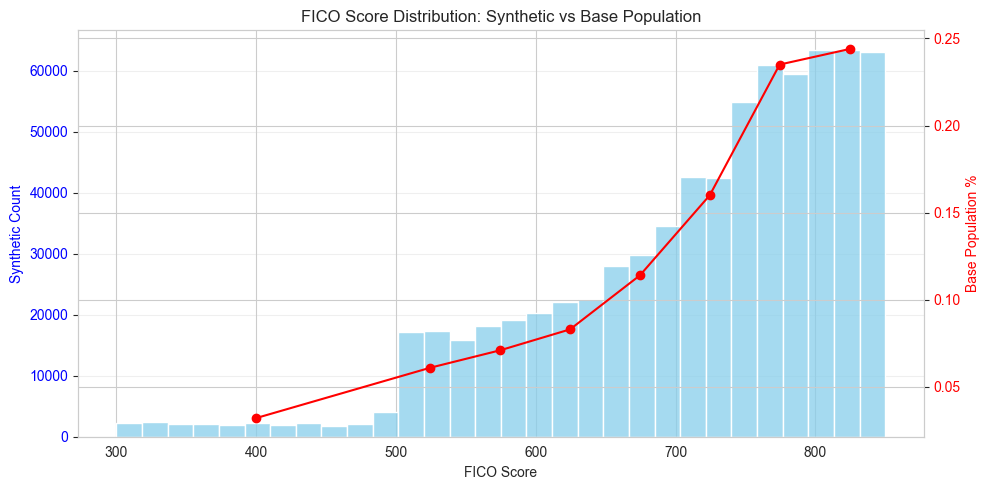

In [14]:
# parsing keys into numeric ranges
fico_ranges = []
for r in fico_base_range_and_percentages.keys():
    low, high = map(int, r.split('-'))
    fico_ranges.append((low, high))

# computing midpoints
midpoints = [np.mean(r) for r in fico_ranges]
percentages = list(fico_base_range_and_percentages.values())


fig, ax1 = plt.subplots(figsize=(10,5))

# plotting histogram of synthetic FICO scores
sns.histplot(df_time_series['fico'], bins=30, kde=False, color='skyblue', ax=ax1)
ax1.set_xlabel("FICO Score")
ax1.set_ylabel("Synthetic Count", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# defining secondary axis for base population percentages
ax2 = ax1.twinx()
midpoints = [np.mean(r) for r in fico_ranges]  # FICO ranges midpoints
percentages = list(fico_base_range_and_percentages.values())
ax2.plot(midpoints, percentages, color='red', marker='o', linestyle='-', label='Base Population')
ax2.set_ylabel("Base Population %", color='red')
ax2.tick_params(axis='y', labelcolor='red')

# adding grid and title
ax1.grid(axis='y', alpha=0.3)
plt.title("FICO Score Distribution: Synthetic vs Base Population")
fig.tight_layout()
save_figure("eda_base_cust_fico_distribution.png")
#fig.savefig("../assets/eda_base_cust_fico_distribution.png", dpi=300)
plt.show()

In [15]:
df_time_series['fico'].describe()

count    720000.000000
mean        712.758519
std         108.629346
min         300.000000
25%         650.000000
50%         742.000000
75%         797.000000
max         850.000000
Name: fico, dtype: float64

*Synthetic FICO scores (blue bars) are compared to the target U.S. population distribution (red line). The generated scores exhibit a realistic distribution, constrained between 300 and 850, with a central tendency near the U.S. population average of approximately 717 and overall proportions consistent with the specified population percentages (Arkali, 2024). This demonstrates that the synthetic dataset closely approximates real-world distributions, providing a solid foundation for acceptance probability modeling and mortgage rate optimization.*

### Income Distribution

Income values are visualized across all synthetic customers and timepoints. This step validates that the generated incomes follow a log-normal distribution with realistic median, P10, and P90 values (based on U.S. Census Bureau, 2025) and remain within plausible bounds for mortgage customers.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_cust_income_distribution.png


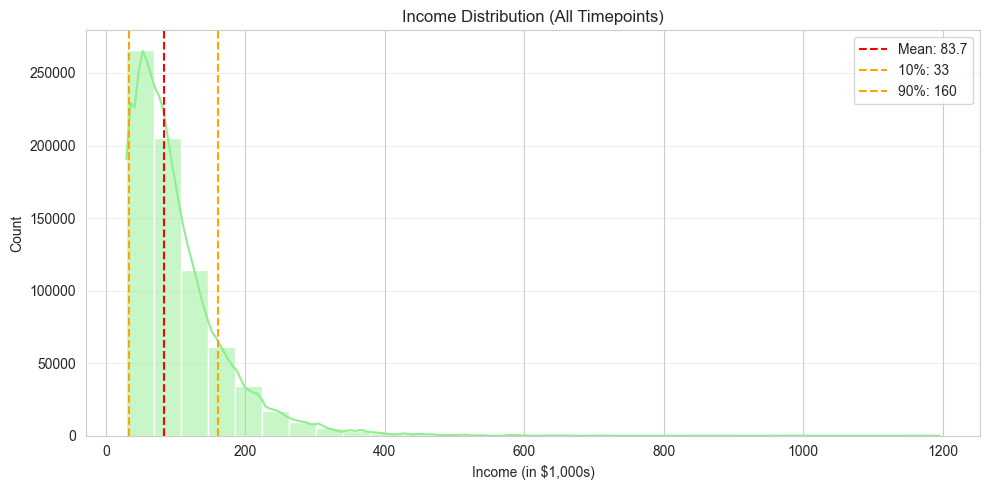

In [16]:
fig, ax = plt.subplots(figsize=(10,5))

# plotting histogram
sns.histplot(df_time_series['income'] / 1000, bins=30, kde=True, color='lightgreen', ax=ax)
ax.set_xlabel("Income (in $1,000s)")
ax.set_ylabel("Count")
ax.set_title("Income Distribution (All Timepoints)")

# adding reference lines for median, p10 and P90
ref_median_income = 83.73  # in thousands
ref_p10_income = 33
ref_p90_income = 160
ax.axvline(ref_median_income, color='red', linestyle='--', label=f"Mean: {ref_median_income:.1f}")
ax.axvline(ref_p10_income, color='orange', linestyle='--', label=f"10%: {ref_p10_income}")
ax.axvline(ref_p90_income, color='orange', linestyle='--', label=f"90%: {ref_p90_income}")

ax.legend()
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
# saving figure
save_figure("eda_base_cust_income_distribution.png")
plt.show()

In [17]:
median_income = df_time_series['income'].median()
p10_income = df_time_series['income'].quantile(0.10)
p90_income = df_time_series['income'].quantile(0.90)
print(f'Median Income: {round(median_income,2)}\n10%: {round(p10_income,2)}\n90%: {round(p90_income,2)}')

Median Income: 83836.84
10%: 38146.43
90%: 186531.79


*The generated income values exhibit a median of approximately 83,684, closely matching the target input median of 83,730. The 10th and 90th percentiles deviate slightly from the nominal targets due to the intrinsic properties of the log-normal distribution used to generate income. The median is well-aligned, and the overall spread produces a realistic distribution for modeling purposes. Overall, the distribution maintains realistic variation and supports credible downstream modeling of acceptance behavior and mortgage-rate optimization.*

---

### Debt-to-Income (DTI) Distribution

DTI values are visualized across all synthetic customers and timepoints. This step confirms that the inverse-U function of income produces realistic financial profiles, with middle-income customers carrying higher relative debt while lower- and higher-income customers maintain lower DTI ratios. Modeling DTI in this way ensures plausible borrower behavior for downstream acceptance probability and mortgage renewal analyses.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_cust_income_distribution.png


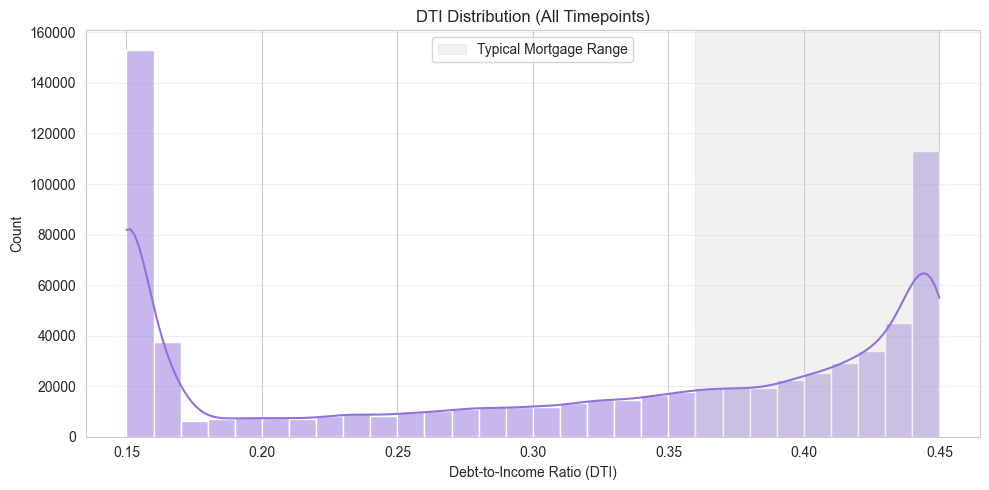

In [18]:
fig, ax = plt.subplots(figsize=(10,5))

# plotting histogram of DTI
sns.histplot(df_time_series['dti'], bins=30, kde=True, color='mediumpurple', ax=ax)
ax.set_xlabel("Debt-to-Income Ratio (DTI)")
ax.set_ylabel("Count")
ax.set_title("DTI Distribution (All Timepoints)")

# highlighting typical DTI range for mortgage eligibility
ax.axvspan(0.36, 0.45, color='lightgrey', alpha=0.3, label='Typical Mortgage Range')
ax.legend()
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
# saving figure
save_figure("eda_base_cust_income_distribution.png")
plt.show()

*The synthetic DTI distribution (purple histogram) reflects the inverse-U relationship with income, producing higher relative debt among middle-income borrowers and lower DTI for both lower- and higher-income groups. The light grey band highlights the typical mortgage eligibility range, generally 36% and up to 45% under certain conditions (Fannie Mae). This modeling approach ensures that the synthetic dataset captures plausible borrower behavior, supporting realistic acceptance probability predictions and mortgage rate optimization.*

### FICO vs DTI Relationship

Customer-facing offered rates incorporate term-dependent funding costs and stochastic spreads to simulate realistic pricing variability. Visualizing the spread distribution by term ensures that longer-term loans carry higher spreads, aligning with lending practices. This check validates the synthetic rate assignments before modeling acceptance behavior.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_cust_fico_vs_dti.png


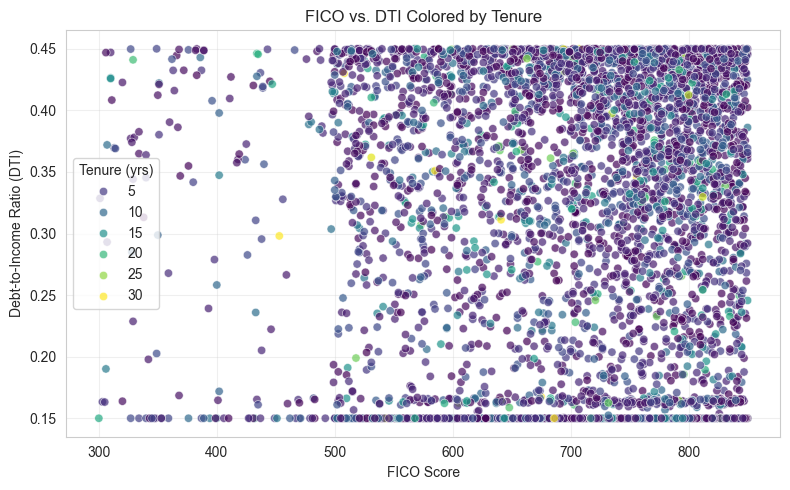

In [19]:
fig, ax = plt.subplots(figsize=(8,5))
sns.scatterplot(
    x='fico', 
    y='dti', 
    hue='tenure_yrs', 
    palette='viridis', 
    data=df_time_series.sample(5000), 
    alpha=0.7,
    ax=ax
)
ax.set_xlabel("FICO Score")
ax.set_ylabel("Debt-to-Income Ratio (DTI)")
ax.set_title("FICO vs. DTI Colored by Tenure")
ax.legend(title='Tenure (yrs)')
ax.grid(alpha=0.3)
fig.tight_layout()
save_figure("eda_base_cust_fico_vs_dti.png")
plt.show()


*The scatter plot illustrates the relationship between FICO scores and debt-to-income (DTI) ratios for a sample of 5,000 customers, with points colored by tenure. The inverse-U function used to generate DTI produces the expected pattern: borrowers with middle-range FICO scores tend to carry higher relative debt, while those with low or high FICO scores maintain lower DTI ratios. Coloring by tenure additionally highlights variations in customer loyalty and mortgage lifecycle stage. This visualization confirms that the synthetic financial profiles are internally consistent and suitable for modeling customer acceptance behavior.*

### Tenure Distribution

Customer tenure is modeled with a right-skewed distribution to reflect typical mortgage behavior: most borrowers stay 5–15 years, while a smaller number remain for the full term. This assumption aligns with observed U.S. housing mobility patterns. Using an exponential distribution ensures that tenure values are realistic and provides meaningful context for behavioral attributes such as loyalty and churn risk.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_cust_tenure_distribution.png


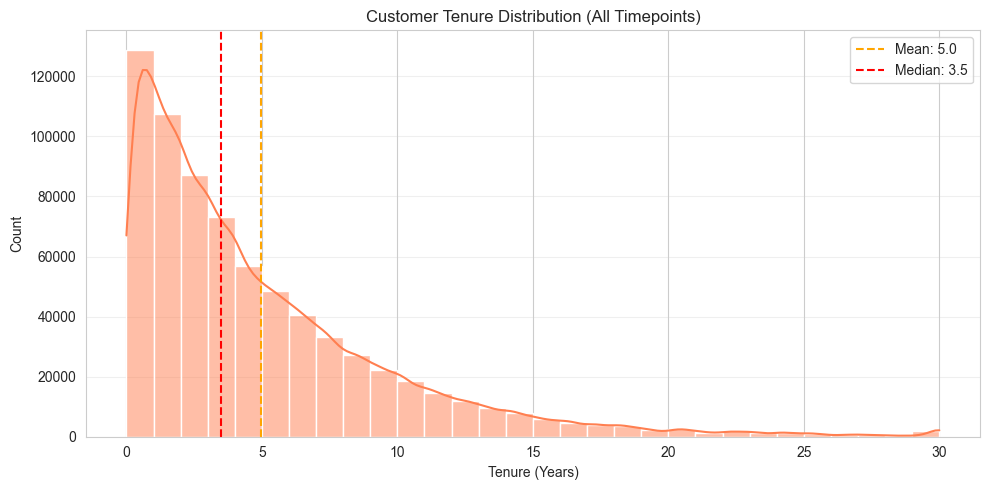

In [20]:
fig, ax = plt.subplots(figsize=(10,5))

# plotting histogram of tenure
sns.histplot(df_time_series['tenure_yrs'], bins=30, kde=True, color='coral', ax=ax)
ax.set_xlabel("Tenure (Years)")
ax.set_ylabel("Count")
ax.set_title("Customer Tenure Distribution (All Timepoints)")

# overlaying mean and median
mean_tenure = df_time_series['tenure_yrs'].mean()
median_tenure = df_time_series['tenure_yrs'].median()
ax.axvline(mean_tenure, color='orange', linestyle='--', label=f"Mean: {mean_tenure:.1f}")
ax.axvline(median_tenure, color='red', linestyle='--', label=f"Median: {median_tenure:.1f}")

ax.legend()
ax.grid(axis='y', alpha=0.3)

fig.tight_layout()
# saving figure
save_figure("eda_base_cust_tenure_distribution.png")
plt.show()

*The histogram shows the distribution of customer tenure across all synthetic timepoints. The exponential generation process produces a right-skewed distribution, with most customers clustered at shorter tenures and a tail of longer-tenure borrowers. Overlayed mean (blue dashed line) and median (green dashed line) indicate central tendency, providing context for loyalty and churn-risk modeling. This distribution aligns with realistic mortgage lifecycles and supports downstream behavioral analyses.*

### Mortgage Term Distribution

Mortgage term lengths are assigned to synthetic customers to reflect common U.S. market patterns, with 15-, 20-, and 30-year loans occurring at different frequencies. This distribution ensures that downstream rate assignment and spread calculations are applied appropriately across terms, providing a realistic foundation for acceptance probability modeling and profitability analysis.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_mort_term_distribution.png


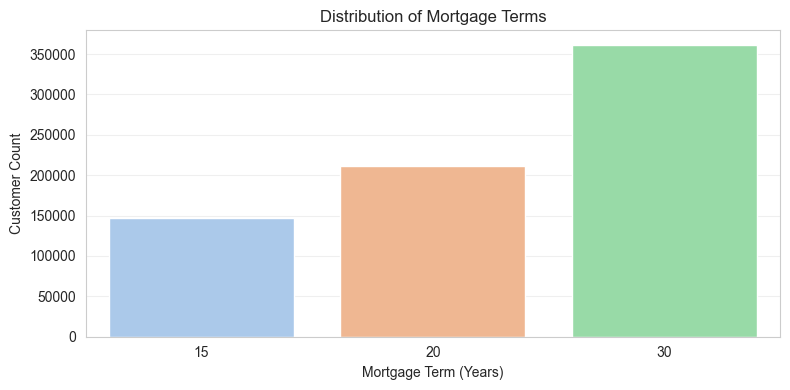

In [21]:
fig, ax = plt.subplots(figsize=(8,4))
sns.countplot(x='term', data=df_time_series, hue = 'term', palette='pastel', ax=ax)  # removed hue
ax.set_xlabel("Mortgage Term (Years)")
ax.set_ylabel("Customer Count")
ax.set_title("Distribution of Mortgage Terms")
ax.grid(axis='y', alpha=0.3)

# removing legend
ax.legend_.remove() if ax.get_legend() else None

fig.tight_layout()
save_figure("eda_base_mort_term_distribution.png")
plt.show()

*This bar chart displays the distribution of mortgage terms across all synthetic customers and timepoints. The synthetic dataset assigns terms according to the intended probabilities (20% 15-year, 30% 20-year, 50% 30-year), reflecting typical market patterns. Understanding the term composition provides context for downstream rate assignments and spread calculations, ensuring that pricing logic is applied appropriately across different loan horizons.*

### Offer Rate Spread by Term

Customer-facing offered rates incorporate term-dependent funding costs and stochastic spreads to simulate realistic pricing variability. Visualizing the spread distribution by term ensures that longer-term loans carry higher spreads, aligning with lending practices. This check validates the synthetic rate assignments before modeling acceptance behavior.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_mort_offer_rate_spread.png


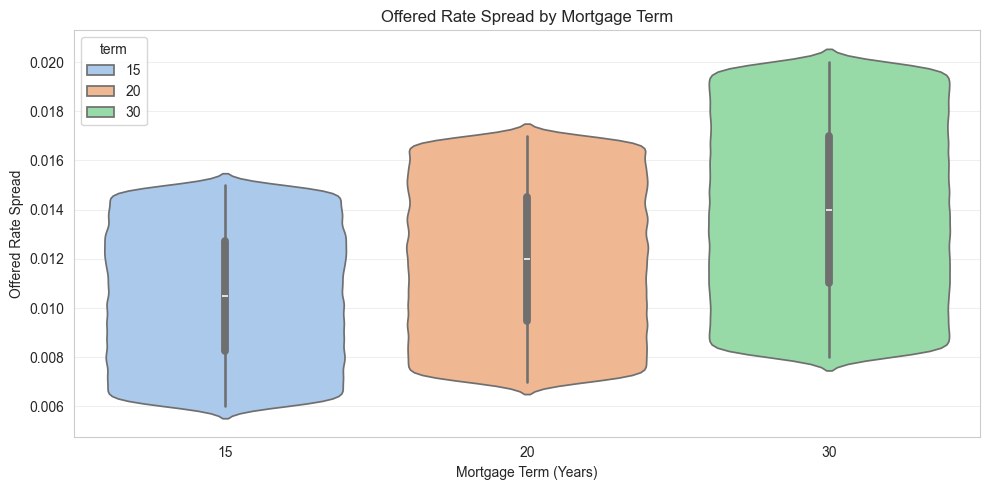

In [22]:
df_time_series['spread'] = df_time_series['offered_rate'] - df_time_series['funding_rate']

fig, ax = plt.subplots(figsize=(10,5))
sns.violinplot(x='term', y='spread', data=df_time_series, hue='term', palette='pastel', ax=ax)
ax.set_xlabel("Mortgage Term (Years)")
ax.set_ylabel("Offered Rate Spread")
ax.set_title("Offered Rate Spread by Mortgage Term")
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
save_figure("eda_base_mort_offer_rate_spread.png")
plt.show()

*This violin plot illustrates the distribution of customer-facing offered rate spreads relative to their funding rate, segmented by mortgage term. The spreads capture both the base funding costs and stochastic variations introduced during synthetic data generation. The plot confirms that longer-term loans tend to carry higher spreads, aligning with realistic lending practices. This visualization validates the plausibility of rate variability used in acceptance modeling.*

### Temporal Stability of Offered Rates

Monthly updates introduce stochastic variation to customer attributes and offered rates over a 36-month panel. Visualizing the average offered rate over time confirms that the simulation produces stable longitudinal dynamics, supporting credible modeling of acceptance behavior, temporal trends, and rate optimization outcomes

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/eda_base_avg_offer_rate_over_time.png


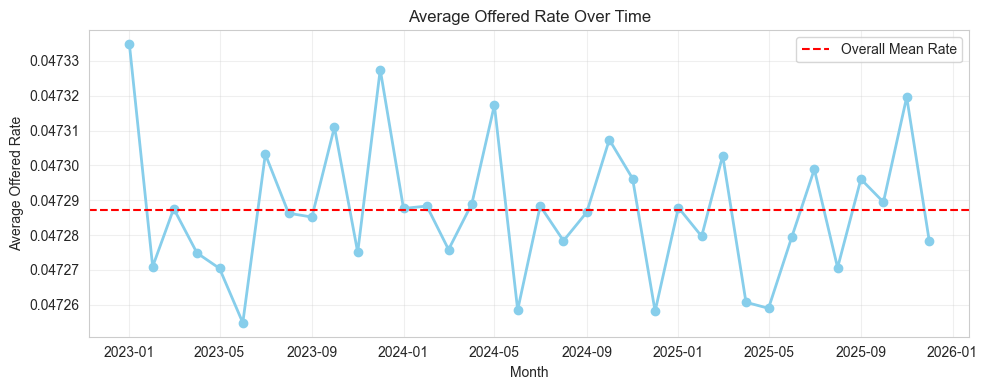

In [23]:
monthly_avg = df_time_series.groupby('month')['offered_rate'].mean()

fig, ax = plt.subplots(figsize=(10,4))  # create figure and axes
ax.plot(monthly_avg.index, monthly_avg.values, marker='o', color='skyblue', linewidth=2)
ax.axhline(monthly_avg.mean(), color='red', linestyle='--', label='Overall Mean Rate')
ax.set_xlabel("Month")
ax.set_ylabel("Average Offered Rate")
ax.set_title("Average Offered Rate Over Time")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
save_figure("eda_base_avg_offer_rate_over_time.png")
plt.show()

*The chart captures the small month-to-month movements in average offered mortgage rates across 36 months. These fluctuations are real but minimal—varying by only about 0.004—demonstrating that the simulation produces natural short-run noise without introducing unrealistic long-term drift. This stability supports reliable downstream modeling of customer acceptance and profit outcomes.*

---

## Acceptance Probability Modeling

This section develops the predictive framework used to estimate how likely a customer is to accept a mortgage renewal offer. Using the synthetic behavioral function defined in the simulation pipeline, acceptance probabilities are generated from customer financial attributes, behavioral traits, and offered rates. These probabilities serve as ground truth labels for training supervised machine learning models.

**Objectives**

* Construct the acceptance function that maps customer characteristics and pricing to an acceptance probability.
* Generate binary acceptance labels (accept/reject) for supervised learning based on these probabilities.
* Train and evaluate baseline predictive models such as logistic regression, Random Forest, and XGBoost.
* Select and tune the best-performing model to serve as the engine for downstream profit optimization

Together, these steps create the foundation for producing data-driven, profit-optimized mortgage rate recommendations.

### Synthetic Acceptance Probability Generator

To generate realistic customer acceptance outcomes, I implemented a behavioral acceptance model that simulates how borrowers respond to mortgage renewal offers. The model combines financial attributes (FICO, income, DTI), behavioral factors (loyalty, rate sensitivity, market awareness), borrower segments, and nonlinear pricing dynamics. These components interact to produce a smooth but highly expressive acceptance probability surface that resembles observed mortgage renewal behavior in real banking environments.  

**Behavioral Segmentation** 

Each customer is assigned to one of five behavioral segments—shopper, loyal, risk-averse, premium, and subprime—each of which influences rate elasticity, loyalty strength, and behavioral volatility. Segment multipliers introduce differentiated customer personas that mirror real-world renewal patterns: shoppers are highly price-sensitive, loyal customers exhibit strong retention even under marginal rate increases, risk-averse customers overweight credit-quality factors, and subprime borrowers show higher behavioral noise.

**Pricing and Rate Sensisitivity** 

Offered rates are generated from the bank’s funding rate with term-specific spreads and segment-adjusted volatility. Acceptance behavior is driven by the difference between the offered rate and the customer’s perceived threshold. Two pricing mechanisms govern sensitivity: a smooth penalty reflecting gradual dissatisfaction with higher spreads, and a threshold shock that sharply decreases acceptance when the offer exceeds an internal reference tolerance. This captures realistic elasticity patterns found in customer renewal datasets.

**Non-linear Financial Effects** 

The acceptance score incorporates nonlinear transformations of income, FICO, DTI, loyalty, and market sensitivity. High-income customers show diminishing marginal resistance to rate increases, FICO influences acceptance through a power-law response that emphasizes both strong and weak credit signals, and DTI contributes a quadratic penalty reflecting financial stress. Interaction terms further model the reinforcing effect of strong credit quality combined with low leverage.

**Noise and Temporal Dynamics** 

The acceptance score incorporates nonlinear transformations of income, FICO, DTI, loyalty, and market sensitivity. High-income customers show diminishing marginal resistance to rate increases, FICO influences acceptance through a power-law response that emphasizes both strong and weak credit signals, and DTI contributes a quadratic penalty reflecting financial stress. Interaction terms further model the reinforcing effect of strong credit quality combined with low leverage.

The resulting acceptance probabilities form the ground truth labels for the predictive models trained in the next section. Because the function encodes realistic behavioral mechanisms—including nonlinear financial effects, price elasticity, and segment-specific renewal dynamics—the machine learning models are trained on behavior that closely resembles real mortgage renewal populations.

In [24]:
def calculate_acceptance_probs(df, add_time_noise=False, term_mean_rate=None, term_std_map=None):
    """
    Synthetic customer acceptance probability model with:
    - Term-based offered rates (mean + spread)
    - Behavioral segments
    - Nonlinear income and rate sensitivity
    - FICO/DTI interactions
    - Segment-specific elasticity and volatility
    - Optional monthly economic shocks
    - Light clipping to reduce extreme probabilities

    Required columns:
    ['fico','income','dti','rate_elasticity','loyalty_factor',
     'market_sensitivity','funding_rate','term']

    Optional:
    'segment' (will be generated if missing)
    'month' if add_time_noise=True

    Returns:
        tuple(np.array of acceptance probabilities [0,1], np.array of offered rates)
    """

    n = len(df)
    fico = df['fico'].to_numpy(float)
    income = df['income'].to_numpy(float)
    dti = df['dti'].to_numpy(float)
    rate_elasticity = df['rate_elasticity'].to_numpy(float)
    loyalty_factor = df['loyalty_factor'].to_numpy(float)
    market_sensitivity = df['market_sensitivity'].to_numpy(float)
    funding_rate = df['funding_rate'].to_numpy(float)
    
    # defining behavioral segments
    if "segment" not in df.columns:
        segments = np.random.choice(
            ["shopper", "loyal", "risk_averse", "premium", "subprime"],
            size=n,
            p=[0.25, 0.20, 0.20, 0.20, 0.15]
        )
    else:
        segments = df['segment'].to_numpy()

    # save as pd.Series to return
    segments_series = pd.Series(segments, index=df.index, name="segment")
    
    # applying segment multipliers
    seg_rate_mult = np.where(segments == "shopper", 1.8,
                     np.where(segments == "loyal", 0.8,
                     np.where(segments == "risk_averse", 1.2,
                     np.where(segments == "premium", 0.7, 1.5))))  # subprime
    seg_loyalty_mult = np.where(segments == "loyal", 2.0, 1.0)
    seg_fico_mult = np.where(segments == "risk_averse", 1.3, 1.0)
    seg_volatility = np.where(segments == "subprime", 0.20, 0.10)

    # generating offers
    mean_spread = 0.005  # base spread above funding
    if term_std_map is None:
        term_std_map = {15: 0.0015, 20: 0.0025, 30: 0.0035}
    
    std_spread_array = np.array([term_std_map.get(t, 0.002) for t in df['term']])
    offered_rate = funding_rate + np.random.normal(
        loc=mean_spread,
        scale=std_spread_array * np.where(segments=="subprime", 1.5, 1.0)
    )

    # enforcing term-specific means
    if term_mean_rate is not None:
        for term, target_mean in term_mean_rate.items():
            mask = df['term'] == term
            if np.any(mask):
                offered_rate[mask] += (target_mean - offered_rate[mask].mean())

    # clipping to reasonable rate bounds
    offered_rate = np.clip(offered_rate, 0.03, 0.09)

    # calculating acceptance score
    raw_rate_diff = offered_rate - funding_rate
    spread_penalty = (
        rate_elasticity *
        np.maximum(raw_rate_diff - 0.01, 0) *
        15
    )
    smooth_penalty = (
        seg_rate_mult
        * rate_elasticity
        * ((raw_rate_diff * 100) ** 1.5)
        * 0.05
    )
    threshold_input = np.maximum(raw_rate_diff - 0.015, 0)
    threshold_shock = -0.25 * threshold_input ** 1.1
    income_factor = 0.15 * (income / (income + 60000))
    fico_norm = (fico - 580) / 270
    fico_factor = seg_fico_mult * 0.15 * np.sign(fico_norm) * np.abs(fico_norm)**1.5
    dti_factor = 0.10 * (1 - dti)**2
    loyalty_term = 0.25 * loyalty_factor * seg_loyalty_mult
    market_term = 0.35 * (1 - market_sensitivity)
    interaction = 0.1 * (fico / 850) * (1 - dti)
    base = 0.25

    score = (
        base
        - spread_penalty
        - smooth_penalty
        + income_factor
        + fico_factor
        + dti_factor
        + loyalty_term
        + market_term
        + interaction
    )

    # adding heteroskedastic noise
    score += np.random.normal(0, seg_volatility, n)

    # optionally introducing monthly shocks
    if add_time_noise and "month" in df.columns:
        months = df["month"].to_numpy()
        unique_months = np.unique(months)
        shocks = np.random.normal(0, 0.05, size=len(unique_months))
        month_shock_map = dict(zip(unique_months, shocks))
        score += np.vectorize(month_shock_map.get)(months)

    # converting to probabilities
    prob = expit(score / 1.25)

    # clipping to avoid extremes
    return np.clip(prob, 0.05, 0.95), offered_rate, segments_series

Using the acceptance probability model, I compute predicted acceptance probabilities and simulate binary acceptance outcomes for all customers.

In [25]:
# defining realistic base term rates
term_mean_rate = {
    15: 0.0565,  # 15-year
    20: 0.061,   # 20-year
    30: 0.063    # 30-year
}

# running the function
df_time_series['accept_prob'], df_time_series['offered_rate'], df_time_series['segment'] = calculate_acceptance_probs(
    df_time_series,
    add_time_noise=False,
    term_mean_rate=term_mean_rate
)

### Creating Binary Labels

This step converts the calculated acceptance probabilities into binary outcomes, producing the target variable for predictive modeling. Each customer-offer record is labeled as 1 (accepted) or 0 (rejected) using a reproducible random draw from a binomial distribution.

In [26]:
# defining accepted (target)
df_time_series["accepted"] = np.random.binomial(1, df_time_series["accept_prob"])

### Acceptance Probability Inspection

After generating acceptance probabilities and simulating binary acceptance outcomes, it is important to validate that the synthetic behavioral model produces realistic patterns. This subsection examines distributions, trends, and relationships in acceptance probabilities across key dimensions—including offered rates, credit scores (FICO), debt-to-income ratios (DTI), mortgage terms, and behavioral segments. Visual inspections confirm that the modeled sensitivities, segment-specific effects, and stochastic variation behave as intended, providing confidence that the dataset is suitable for predictive modeling and downstream profit-optimization experiments

#### Mortgage Renewal Acceptance Response Curve

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/accpt_prob_gen_acceptance_response_curve.png


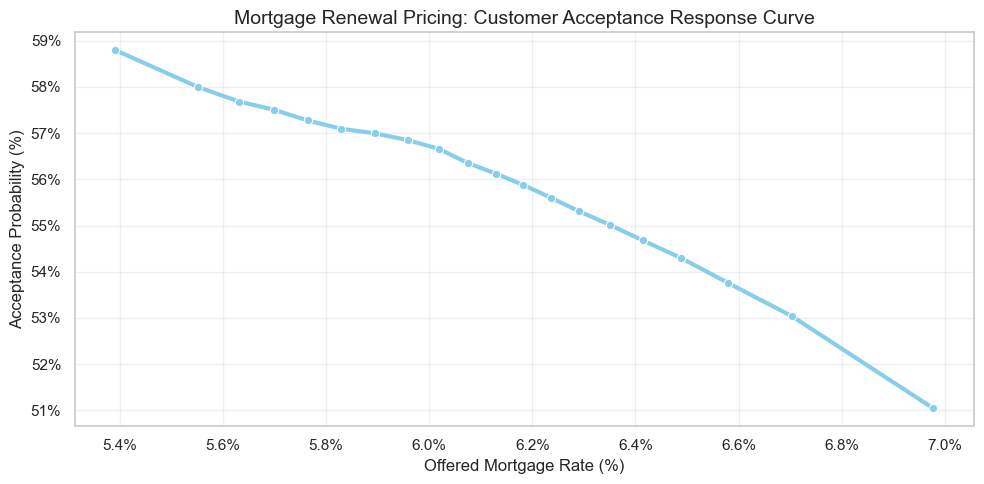

In [27]:
# Create rate bins
rate_curve = (
    df_time_series
    .groupby(
        pd.qcut(df_time_series["offered_rate"], q=20),
        observed=True
    )
    .agg(
        avg_offered_rate=("offered_rate", "mean"),
        avg_accept_prob=("accept_prob", "mean")
    )
    .reset_index(drop=True)
)

# Seaborn pastel theme
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10,5))

sns.lineplot(
    data=rate_curve,
    x="avg_offered_rate",
    y="avg_accept_prob",
    marker="o",
    linewidth=3,
    color="skyblue"
)

plt.title(
    "Mortgage Renewal Pricing: Customer Acceptance Response Curve",
    fontsize=14
)

plt.xlabel("Offered Mortgage Rate (%)")
plt.ylabel("Acceptance Probability (%)")

# Format axes as percentages
plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.1%}")
)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

plt.grid(alpha=0.3)

plt.tight_layout()

save_figure("accpt_prob_gen_acceptance_response_curve.png")

plt.show()

#### Term Rate Mean Validation

This table summarizes the mean and standard deviation of offered rates, calculated acceptance probabilities, and binary accepted outcomes across mortgage terms (15, 20, 30 years). As expected, longer-term loans carry slightly higher offered rates and correspondingly lower acceptance probabilities, reflecting realistic pricing behavior. The accepted column demonstrates that the binomial sampling produces plausible acceptance frequencies consistent with the modeled probabilities, providing confidence in the synthetic target labels.

In [28]:
accpt_mean_summary_table = df_time_series.groupby("term")[["offered_rate","accept_prob","accepted"]].agg(['mean','std'])
accpt_mean_summary_table

offered_rate           accept_prob            accepted          
             mean       std        mean       std      mean       std
term                                                                 
15         0.0565  0.001636    0.570788  0.046710  0.571608  0.494847
20         0.0610  0.002728    0.555990  0.051539  0.555556  0.496905
30         0.0630  0.003805    0.555907  0.054103  0.556015  0.496853

#### Acceptance Probability Distribution

Using the calculated acceptance probabilities for each customer, I visualize the distribution across the 36-month panel. Monthly stochastic updates to customer attributes and offered rates introduce realistic variation, and this visualization confirms that the modeled probabilities produce stable, plausible patterns of acceptance behavior. Inspecting the distribution ensures the synthetic data supports credible supervised learning and downstream rate-optimization analyses,

In [29]:
baseline_accepted_probs = df_time_series['accepted'].value_counts(normalize=True)
baseline_accepted_probs

accepted
1    0.559068
0    0.440932
Name: proportion, dtype: float64

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/accpt_prob_gen_base_distribution.png


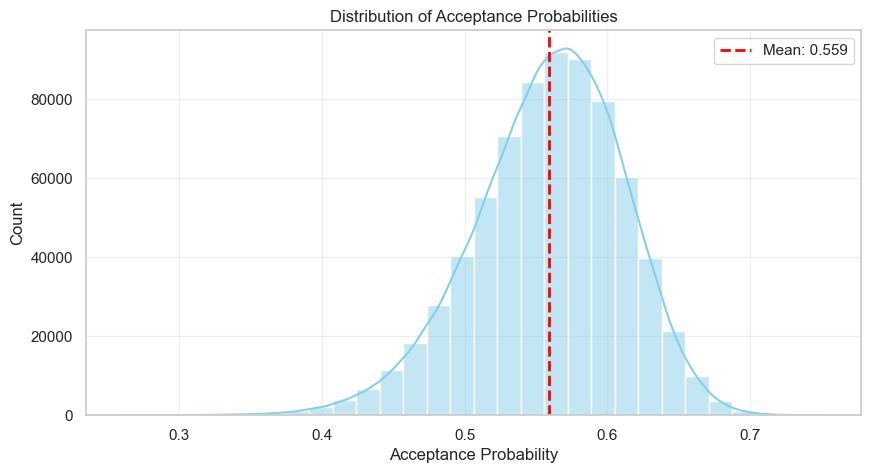

In [30]:
plt.figure(figsize=(10,5))

# Plot histogram
sns.histplot(df_time_series['accept_prob'], bins=30, kde=True, color='skyblue')

# Overlay mean
mean_prob = df_time_series['accept_prob'].mean()
plt.axvline(mean_prob, color='red', linestyle='--', linewidth=2, label=f"Mean: {mean_prob:.3f}")

# Titles and labels
plt.title("Distribution of Acceptance Probabilities")
plt.xlabel("Acceptance Probability")
plt.ylabel("Count")
plt.legend()
plt.grid(alpha=0.3)
save_figure("accpt_prob_gen_base_distribution.png")
plt.show()

*The histogram shows the distribution of customer acceptance probabilities across the full synthetic dataset. The probabilities reflect the combined effects of customer financial profiles, behavioral attributes, and offered mortgage rates. The overlaid mean (red dashed line) highlights the central tendency, confirming that the simulation produces realistic variation in acceptance behavior without extreme clustering, supporting credible modeling of binary accepted outcomes and downstream rate optimization.*

#### Offer Rate Distribution by Term

This visualization summarizes the distribution of offered mortgage rates for each term (15, 20, 30 years). By combining a boxplot with a small sample of individual points, the chart highlights both the central tendency and the spread of rates, including any outliers. This step ensures that the term-specific rate assignment in the synthetic dataset produces plausible variability for modeling acceptance behavior

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/accpt_prob_gen_offer_rate_by_term.png


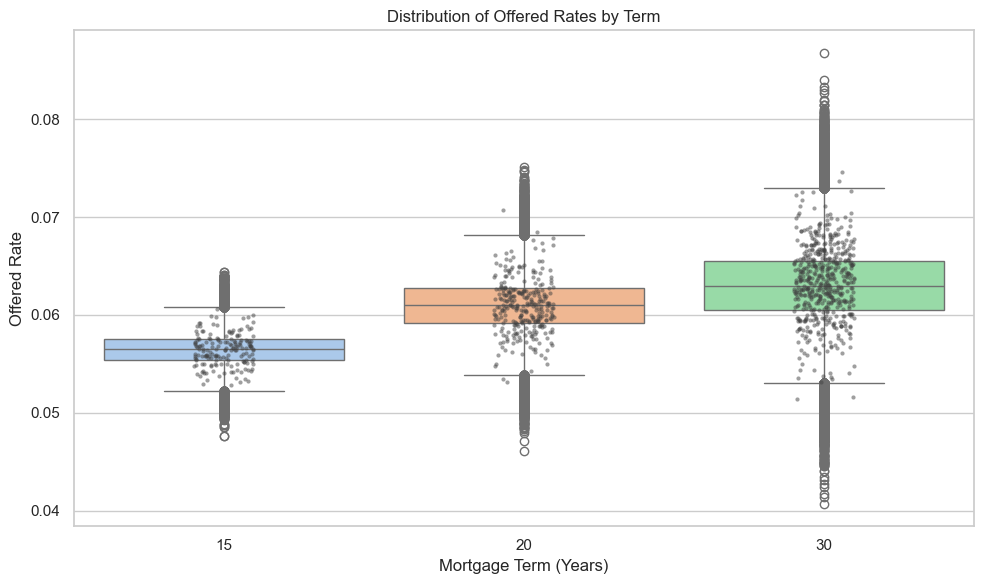

In [31]:
# Figure setup
fig, ax = plt.subplots(figsize=(10, 6))

# Boxplot: summarizes distribution by term
sns.boxplot(
    x='term',
    y='offered_rate',
    data=df_time_series,
    hue='term',
    palette="pastel",
    ax=ax
)

# Optional: overlay a small random sample of points for context
sample_df = df_time_series.sample(n=1000, random_state=42)
sns.stripplot(
    x='term',
    y='offered_rate',
    data=sample_df,
    color=".25",  # dark grey points
    size=3,
    alpha=0.5,
    jitter=True,
    ax=ax
)

# Labels and title
ax.set_xlabel("Mortgage Term (Years)")
ax.set_ylabel("Offered Rate")
ax.set_title("Distribution of Offered Rates by Term")

# Remove legend
if ax.get_legend() is not None:
    ax.get_legend().remove()

save_figure("accpt_prob_gen_offer_rate_by_term.png")
plt.tight_layout()
plt.show()

*The boxplot displays the median, interquartile range, and potential outliers of offered rates across mortgage terms. The overlaid points provide context for the distribution’s spread and natural stochastic variation. As expected, longer-term loans generally carry slightly higher rates, confirming that the synthetic data aligns with realistic term-dependent pricing structures and supports credible modeling of acceptance probabilities*

#### Acceptance Probability by Segment

Boxplots summarize acceptance probabilities across behavioral segments defined in the synthetic dataset. This analysis checks that segment-specific multipliers in the acceptance function produce distinct patterns in customer responsiveness.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/accpt_prob_gen_offer_rates_by_segment.png


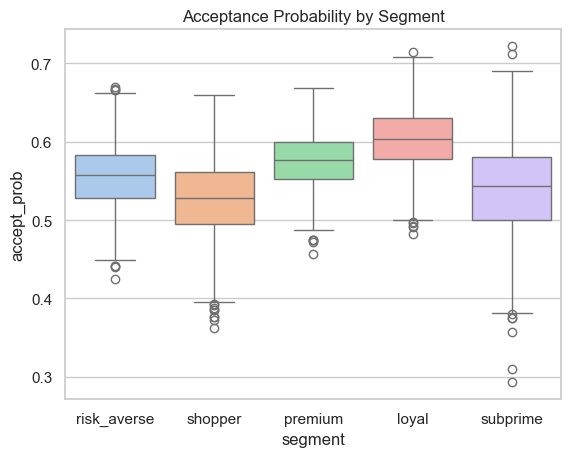

In [32]:
sns.boxplot(x='segment', y='accept_prob', data=df_time_series.sample(5000),hue="segment", palette="pastel")
plt.title("Acceptance Probability by Segment")
save_figure("accpt_prob_gen_offer_rates_by_segment.png")
plt.show()

*Segment-level acceptance probabilities reveal meaningful differences in behavior. "Loyal" customers exhibit the highest acceptance rates, followed by "risk_averse" and then "premium" borrowers. The elevated acceptance of "risk_averse" customers aligns with their tendency to shop less frequently, while "shopper" and "subprime" segments remain most sensitive to offered rates. This confirms that the segmentation logic produces realistic behavioral patterns consistent with expected customer tendencies.*

#### Feature Correlations

This heatmap displays pairwise correlations between key customer attributes, offered rates, and acceptance probabilities. Inspecting these relationships helps confirm that the synthetic dataset is internally consistent and that feature interactions are plausible.

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/accpt_prob_gen_feature_correlations.png


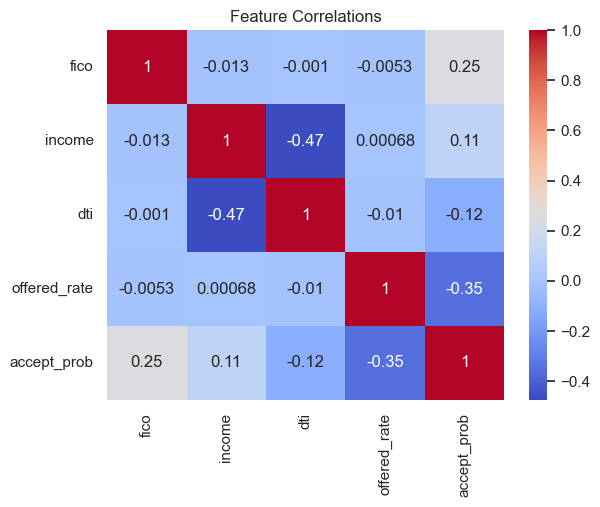

In [33]:
corr = df_time_series[['fico','income','dti','offered_rate','accept_prob']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Feature Correlations")
save_figure("accpt_prob_gen_feature_correlations.png")
plt.show()

*The correlation matrix highlights key relationships in the synthetic dataset. Acceptance probability is strongly positively correlated with FICO and moderately with income, while negatively correlated with DTI, reflecting realistic borrower behavior. Offered rates show minimal direct correlation with acceptance, consistent with the stochastic generation and behavioral segmentation. The inverse-U relationship between income and DTI is also evident. Overall, these correlations confirm that the synthetic features provide meaningful and internally consistent signals for predictive modeling.*

---

### Acceptance Probability Model Training and Evaluation

This section trains and evaluates predictive models using the synthetic dataset to estimate the probability that each customer will accept a mortgage offer. Accurate probability estimates are essential for reliable downstream profit optimization, ensuring that the selected model not only predicts acceptance effectively but also supports informed pricing and offer strategies.  

Logistic Regression, Random Forest and XGBoost models are compared to identify the approach that provides the most reliable probability estimates while maintaining predictive accuracy. The best-performing model will be used in subsequent profit-optimization experiments.

#### Data Preparation

Before training models, the dataset is prepared to ensure robust, reproducible evaluation. Selected features capture customer financial attributes (FICO, income, DTI, tenure), offer characteristics (term, offered rate, rate elasticity), and behavioral modifiers (loyalty factor, market sensitivity).  

To prevent data leakage, the dataset is split by unique customer IDs, keeping all observations for each customer together. This produces X_train/y_train for model fitting and X_test/y_test for evaluation.  

Key preprocessing steps include:
* Standardizing numeric features to put all continuous variables on a consistent scale.
* One-hot encoding categorical variables (segment, term) to convert them into a model-ready numeric format.
* Preserving all transformations for future inference and reproducibility.

*Splitting training and test data*

In [34]:
# defining features and target from synthetic dataset
features = [
    "fico", "income", "dti", "tenure_yrs", "term", "offered_rate",
    "rate_elasticity", "loyalty_factor", "market_sensitivity", "segment"
]
target = "accepted"

# splitting by unique customer IDs for train/test
customer_ids = df_time_series["customer_id"].unique()
train_ids, test_ids = train_test_split(customer_ids, test_size=0.3, random_state=42)

df_train = df_time_series[df_time_series["customer_id"].isin(train_ids)].copy()
df_test = df_time_series[df_time_series["customer_id"].isin(test_ids)].copy()

# splitting df_train and df_test
X_train = df_train[features]
y_train = df_train[target]
X_test = df_test[features]
y_test = df_test[target]

*Defining numeric and categorical features, standard Scaler and preprocessor to use in pipelines*

In [35]:
# Define feature groups
numeric_features = ["fico", "income", "dti", "tenure_yrs", "offered_rate",
                    "rate_elasticity", "loyalty_factor", "market_sensitivity"]
categorical_features = ["term", "segment"]

# ColumnTransformer for preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop=None, sparse_output=False), categorical_features)
])

#### Model Training

Multiple baseline models are trained to estimate customer acceptance probabilities, including Logistic Regression, Random Forest, and XGBoost. Each model is evaluated on the training set to establish baseline performance and guide selection of the best-performing approach.  

For the selected model, hyperparameter tuning is performed to optimize predictive metrics such as ROC-AUC, Brier Score, and calibration. This ensures the model fits the training data effectively while providing reliable probability estimates for unseen customers, which is critical for downstream profit-optimization

*Building the  model pipelines*

In [36]:
# Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

# XGBoost pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        objective="binary:logistic",
        random_state=42,
        n_jobs=-1,
        eval_metric="logloss"
    ))
])

*Fitting each model with training data*

In [37]:
# fitting each model
lr_pipeline.fit(X_train, y_train)
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['fico','income','dti',...,'loyalty_factor','market_sensitivity','segment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, 

*Predicting Acceptance Probabilities with test data*

In [38]:
df_test["lr_prob"] = lr_pipeline.predict_proba(X_test)[:,1]
df_test["rf_prob"] = rf_pipeline.predict_proba(X_test)[:,1]
df_test["xgb_prob"] = xgb_pipeline.predict_proba(X_test)[:,1]

*Taking a look at the first few rows of the output*

In [39]:
print(df_test[["customer_id","offered_rate","accepted","lr_prob","rf_prob","xgb_prob"]].head())

   customer_id  offered_rate  accepted   lr_prob   rf_prob  xgb_prob
0            1      0.060410         1  0.614250  0.602387  0.631486
3            4      0.055855         1  0.561624  0.556559  0.553994
5            6      0.061754         0  0.596627  0.594303  0.614283
6            7      0.066867         0  0.454616  0.443834  0.412753
8            9      0.062455         0  0.525394  0.524810  0.534339


#### Evaluation and Diagnostics

Baseline models are compared using a combination of quantitative metrics and visual diagnostics. ROC-AUC evaluates the ability to discriminate between Accepted and Rejected offers, while Brier Score Loss measures the accuracy and reliability of predicted probabilities.  

Visual diagnostics—including probability distribution plots and calibration curves—highlight areas of over- or under-confidence in predictions, and ROC curves compare ranking performance across thresholds. Together, these evaluations indicate that XGBoost provides the strongest combination of discrimination and calibration, making it the preferred model for targeted hyperparameter tuning in the next stage.

**ROC-AUC and Brier Scores**

The table shows the performance metrics for the baseline models on the synthetic dataset. While logistic regression and random forest achieved slightly higher ROC-AUC and lower Brier scores, tuning logistic regression did not meaningfully improve predictive performance. XGBoost, however, better captures the full probability distribution of customer acceptance, providing more realistic and nuanced probability estimates. This improved calibration makes it the preferred model for downstream profit-optimization and targeted rate recommendations.

*Evaluating with ROC-AUC and Brier Score*

In [40]:
# Dictionary to store results
metrics = {}

for model_name in ["lr_prob", "rf_prob", "xgb_prob"]:
    y_prob = df_test[model_name]
    auc = roc_auc_score(df_test["accepted"], y_prob)
    brier = brier_score_loss(df_test["accepted"], y_prob)
    metrics[model_name] = {"ROC-AUC": auc, "Brier Score": brier}

pd.DataFrame(metrics).T

,ROC-AUC,Brier Score
lr_prob,0.554463,0.244190
rf_prob,0.552152,0.244401
xgb_prob,0.549209,0.244713


#### Actual vs Predicted Probability Distributions

The Kernel Density Estimation (KDE) plot compares predicted acceptance probabilities from each model to the true probabilities generated by the calculate_acceptance_probs function. XGBoost captures the underlying distribution most accurately, reflecting the heterogeneity in customer behavior and rate sensitivity. While occasional extreme values indicate some overconfident predictions, the overall alignment demonstrates that XGBoost provides well-calibrated probability estimates suitable for profit-optimized offer strategies.

*Defining models and color palatte for visualizations*

In [41]:
models = ["lr_prob", "rf_prob", "xgb_prob"]

palette = {
    "Actual": "mediumslateblue",
    "Logistic Regression": "skyblue",
    "Random Forest": "lightgreen",
    "XGBoost": "salmon"
}

*Plotting Actual vs Predicted Probability Distributions*

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/pred_accpt_prob_distribution.png


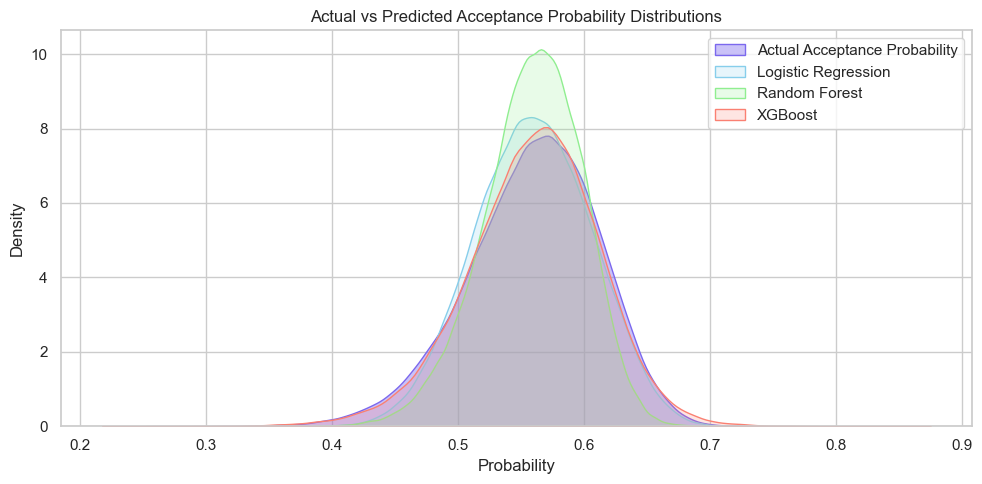

In [42]:
plt.figure(figsize=(10,5))

sns.kdeplot(df_test["accept_prob"], label="Actual Acceptance Probability", fill=True, color=palette["Actual"], alpha=0.4)
sns.kdeplot(df_test["lr_prob"], label="Logistic Regression", fill=True, color=palette["Logistic Regression"], alpha=0.2)
sns.kdeplot(df_test["rf_prob"], label="Random Forest", fill=True, color=palette["Random Forest"], alpha=0.2)
sns.kdeplot(df_test["xgb_prob"], label="XGBoost", fill=True, color=palette["XGBoost"], alpha=0.2)

plt.title("Actual vs Predicted Acceptance Probability Distributions")
plt.xlabel("Probability")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
save_figure("pred_accpt_prob_distribution.png")
plt.show()

#### Calibration Curves

Calibration curves compare predicted probabilities to actual outcomes, with the diagonal representing perfect calibration. Initially, XGBoost predictions deviate more from the ideal line than Logistic Regression or Random Forest, showing some under- or overestimation of acceptance probabilities. As the probability range progresses, XGBoost adjusts and aligns more closely with the diagonal, capturing the overall trend in customer behavior. Random Forest remains closest to the perfect calibration curve throughout, indicating the most consistent and reliable probability estimates across all ranges.

*Plotting the calibration curves*

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/pred_accpt_prob_calibration_curves.png


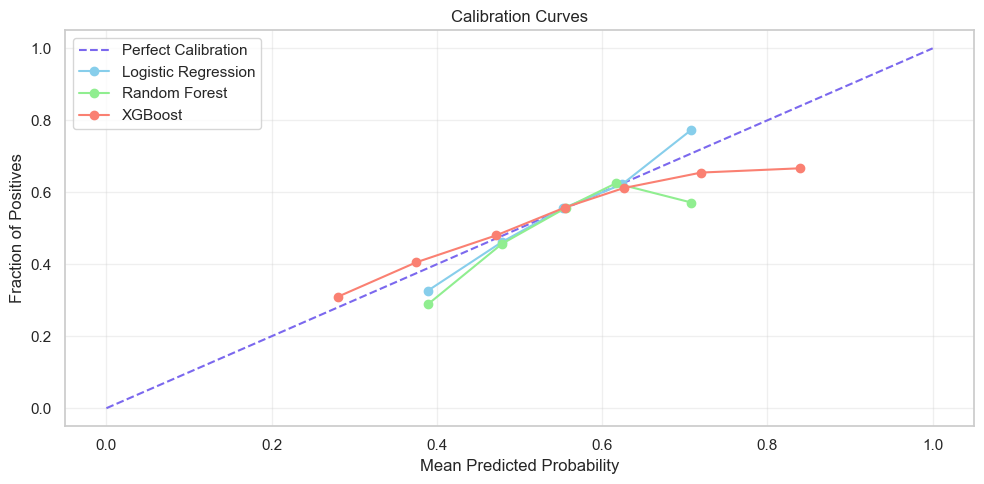

In [43]:
plt.figure(figsize=(10,5))

# Actual (perfect calibration)
plt.plot([0,1], [0,1], linestyle="--", color=palette["Actual"], label="Perfect Calibration")

# Logistic Regression
prob_true, prob_pred = calibration_curve(df_test["accepted"], df_test["lr_prob"], n_bins=10)
plt.plot(prob_pred, prob_true, marker='o', label="Logistic Regression", color=palette["Logistic Regression"])

# Random Forest
prob_true, prob_pred = calibration_curve(df_test["accepted"], df_test["rf_prob"], n_bins=10)
plt.plot(prob_pred, prob_true, marker='o', label="Random Forest", color=palette["Random Forest"])

# XGBoost
prob_true, prob_pred = calibration_curve(df_test["accepted"], df_test["xgb_prob"], n_bins=10)
plt.plot(prob_pred, prob_true, marker='o', label="XGBoost", color=palette["XGBoost"])

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("Calibration Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("pred_accpt_prob_calibration_curves.png")
plt.show()

#### ROC Curves

All three models produce the expected arch-shaped ROC curves, indicating a meaningful ability to distinguish between accepted and rejected offers. The curves are closely clustered, but Logistic Regression sits slightly nearer to the top-left corner, reflecting marginally stronger discrimination performance compared with Random Forest and XGBoost. Although the differences are small, this suggests that Logistic Regression is the most effective at ranking customers by likelihood of acceptance.

*Plotting the calibration curves*

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/pred_accpt_prob_roc_curves.png


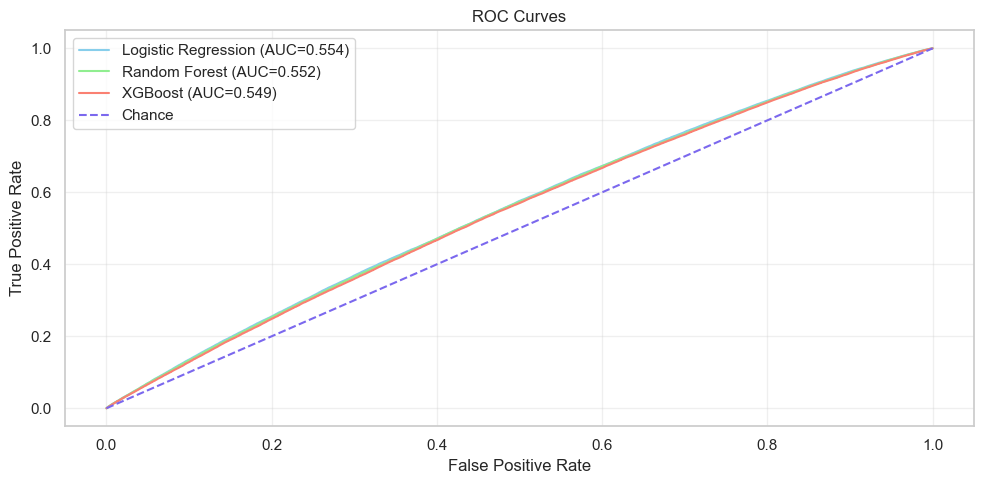

In [44]:
plt.figure(figsize=(10,5))

# Logistic Regression
fpr_lr, tpr_lr, _ = roc_curve(df_test["accepted"], df_test["lr_prob"])
roc_auc_lr = roc_auc_score(df_test["accepted"], df_test["lr_prob"])
plt.plot(fpr_lr, tpr_lr, color=palette["Logistic Regression"], 
         label=f"Logistic Regression (AUC={roc_auc_lr:.3f})")

# Random Forest
fpr_rf, tpr_rf, _ = roc_curve(df_test["accepted"], df_test["rf_prob"])
roc_auc_rf = roc_auc_score(df_test["accepted"], df_test["rf_prob"])
plt.plot(fpr_rf, tpr_rf, color=palette["Random Forest"], 
         label=f"Random Forest (AUC={roc_auc_rf:.3f})")

# XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(df_test["accepted"], df_test["xgb_prob"])
roc_auc_xgb = roc_auc_score(df_test["accepted"], df_test["xgb_prob"])
plt.plot(fpr_xgb, tpr_xgb, color=palette["XGBoost"], 
         label=f"XGBoost (AUC={roc_auc_xgb:.3f})")

# Chance line
plt.plot([0,1], [0,1], linestyle="--", color=palette["Actual"], label="Chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
save_figure("pred_accpt_prob_roc_curves.png")
plt.tight_layout()
plt.show()

#### Final Acceptance Probability Model Tuning

Initial tuning efforts focused on Logistic Regression, given its simplicity, interpretability, and strong calibration properties. However, despite adjusting regularization strength and penalty terms, the model showed limited improvement and continued to underfit the underlying acceptance patterns in the data.  The results are included in the Appendix at the end of this notebook.

Because of this plateau in performance and the need for more flexible probability modeling in the downstream rate optimization step, I transitioned to XGBoost as the final model to tune. XGBoost demonstrated a much stronger ability to capture nonlinear relationships and reproduce the true distribution of acceptance probabilities, even though its baseline metrics were only slightly different from the other models.  

In this section, I therefore focus on tuning the XGBoost classifier, refining parameters such as tree depth, learning rate, and regularization strength to improve both discrimination and probability calibration. This shift ensures that the final model feeding into the optimization engine is expressive enough to capture real behavioral patterns while still producing usable, stable probability estimates.

*Tuning the XGBoost Model*

In [45]:
# defining the hyperparameter grid for tuning
param_grid_xgb = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 6],
    "model__learning_rate": [0.01, 0.05, 0.1],
}

# setting up GridSearchCV
grid_search_xgb = GridSearchCV(
    xgb_pipeline,
    param_grid_xgb,
    scoring="roc_auc",
    cv=3,
    n_jobs=1,
    verbose=0
)

# fitting the tuned XGBoost model
grid_search_xgb.fit(X_train, y_train)

# returning best params and ROC-AUC
print("Best parameters:", grid_search_xgb.best_params_)
print("Best ROC-AUC:", grid_search_xgb.best_score_)

# saving best estimator to use in rate optimizer
best_xgb_pipeline = grid_search_xgb.best_estimator_

Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}
Best ROC-AUC: 0.5518682962095877


*Calibrating the best xgboost pipeline to improve alignment of predicted acceptance probabilities with observed outcomes*

In [46]:
# wrapping the best XGBoost pipeline
calibrated_xgb = CalibratedClassifierCV(best_xgb_pipeline, method='sigmoid', cv=3)
calibrated_xgb.fit(X_train, y_train)

# returning calibrated probabilities
y_pred_proba_cal = calibrated_xgb.predict_proba(X_test)[:, 1]

*Plotting baseline, tuned and calibrated Acceptance Probability distributions*

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/tuned_xgb_pred_accpt_prob_distribution.png


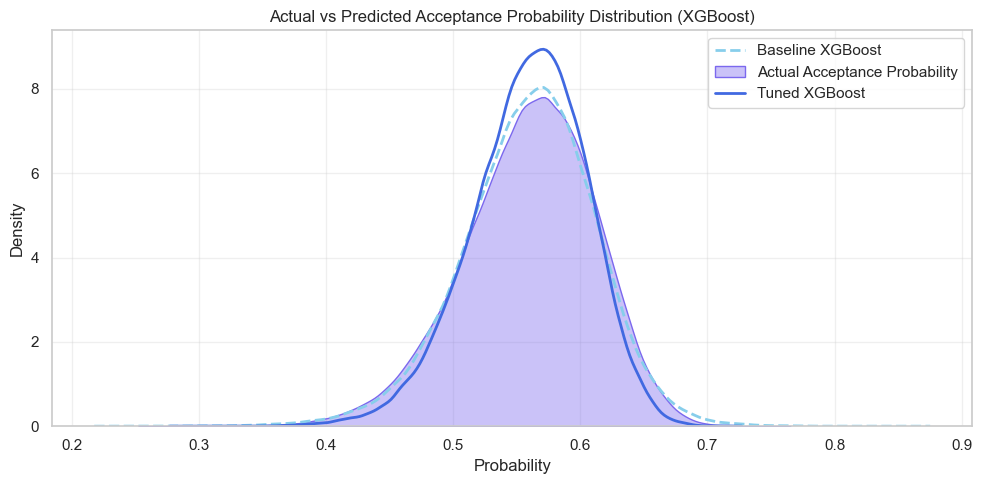

In [47]:
plt.figure(figsize=(10,5))

# plotting Baseline XGBoost Regression probabilities
sns.kdeplot(
    df_test["xgb_prob"], 
    label="Baseline XGBoost", 
    color="skyblue", 
    linestyle="--", 
    lw=2
)

# plotting actual probabilities from the synthetic generator
sns.kdeplot(
    df_test["accept_prob"], 
    label="Actual Acceptance Probability", 
    fill=True, 
    color="mediumslateblue", 
    alpha=0.4
)

# plotting tuned XGBoost probabilities
sns.kdeplot(
    y_pred_proba_cal, 
    label="Tuned XGBoost", 
    color="royalblue",  # choose a distinct color
    lw=2
)

plt.title("Actual vs Predicted Acceptance Probability Distribution (XGBoost)")
plt.xlabel("Probability")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("tuned_xgb_pred_accpt_prob_distribution.png")
plt.show()

*Saving probabilities for visual inspection*

In [48]:
# storing probabilities from each version of the model
y_xgb_base = df_test["xgb_prob"]
y_xgb_tuned = best_xgb_pipeline.predict_proba(X_test)[:, 1]
y_xgb_cal = calibrated_xgb.predict_proba(X_test)[:, 1]

*Inspecting the calibration curves after tuning*

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/tuned_xgb_pred_accpt_calibration_curve_comparison.png


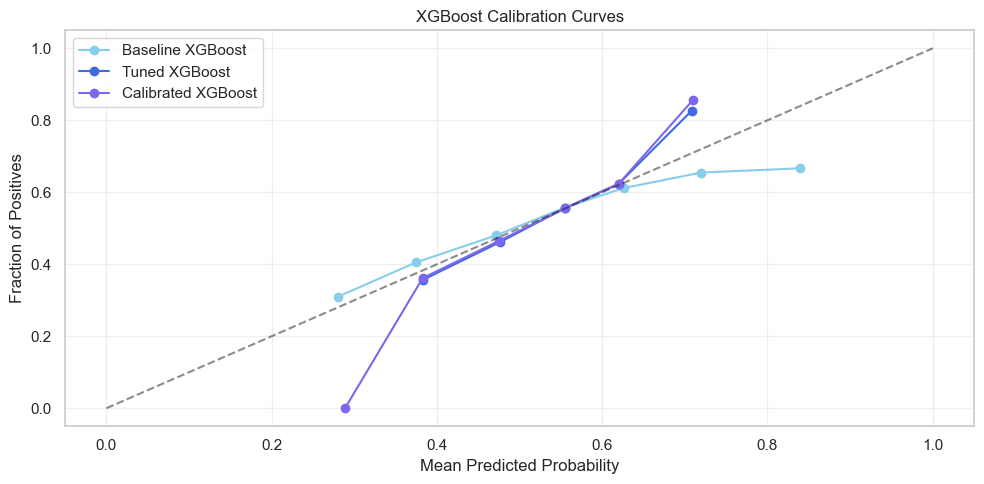

In [49]:
plt.figure(figsize=(10,5))

for probs, label, color in [
    (y_xgb_base, "Baseline XGBoost", "skyblue"),
    (y_xgb_tuned, "Tuned XGBoost", "royalblue"),
    (y_xgb_cal, "Calibrated XGBoost", "mediumslateblue")
]:
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=10)
    plt.plot(mean_pred, frac_pos, marker='o', label=label, color=color)

plt.plot([0,1], [0,1], "k--", alpha=0.5)
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.title("XGBoost Calibration Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("tuned_xgb_pred_accpt_calibration_curve_comparison.png")
plt.show()

*Inspecting the ROC Curves after tuning*

Saved: /Users/rnitto/Projects/portfolio/mortgage_renewal_pricing_optimization/outputs/figures/tuned_xgb_pred_accpt_roc_curve_comparison.png


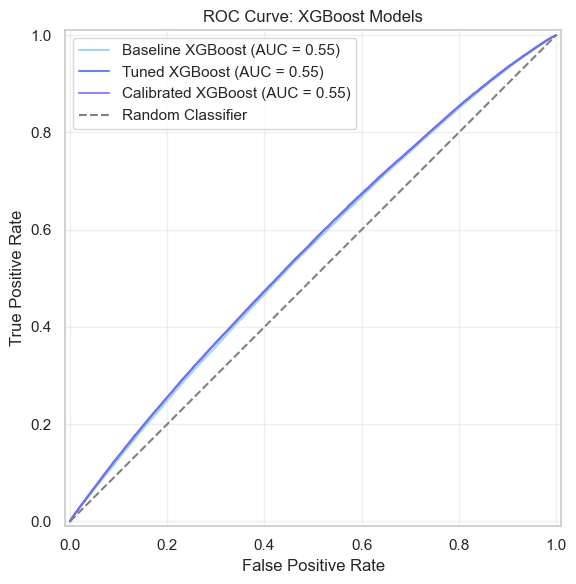

In [50]:
y_true = df_test["accepted"]

plt.figure(figsize=(8,6))
ax = plt.gca()  # get current axes

# plotting baseline XGBoost
RocCurveDisplay.from_predictions(
    y_true, y_xgb_base, name="Baseline XGBoost", 
    curve_kwargs={"color":"skyblue", "alpha":0.8}, ax=ax
)

# plotting tuned XGBoost
RocCurveDisplay.from_predictions(
    y_true, y_xgb_tuned, name="Tuned XGBoost", 
    curve_kwargs={"color":"royalblue", "alpha":0.8}, ax=ax
)

# plotting calibrated XGBoost
RocCurveDisplay.from_predictions(
    y_true, y_xgb_cal, name="Calibrated XGBoost", 
    curve_kwargs={"color":"mediumslateblue", "alpha":0.8}, ax=ax
)

# adding reference diagonal line
ax.plot([0,1], [0,1], linestyle="--", color="gray", label="Random Classifier")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve: XGBoost Models")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
save_figure("tuned_xgb_pred_accpt_roc_curve_comparison.png")
plt.show()

#### Final Acceptance Prediction Model Selection

I evaluated several models to predict customer acceptance probabilities, including baseline Logistic Regression, tuned Logistic Regression, and XGBoost. Initial tuning of Logistic Regression did not improve the fit to the observed probability distribution, despite comparable ROC-AUC scores.  

Visual inspection of the predicted acceptance distributions indicated that XGBoost better captured the underlying shape of the true acceptance probabilities. I further attempted hyperparameter optimization and probability calibration for XGBoost. While tuning and calibration slightly improved ROC-AUC (by approximately 0.004), the baseline XGBoost model still provided the closest match to the observed probability distribution.  

Based on these findings, I selected the baseline XGBoost model for use in the Mortgage Rate Optimization step. This choice ensures that the predicted probabilities used in optimization closely reflect the true customer behavior, as defined by the synthetic data generator and parameters

---

## Mortgage Renewal Offer Rate Optimization

In this section, we translate the predicted customer acceptance probabilities into actionable mortgage-renewal pricing decisions.  

**Objectives**  

* Generate candidate offer rates for each customer.
* Compute expected profit for each candidate rate using predicted acceptance probabilities.
* Identify the optimal offer rate that maximizes expected profit while managing the risk of customer churn.
* Visualize the distributions of offered versus optimized rates and the corresponding expected profits.

This approach operationalizes the predictive model, providing a data-driven pricing strategy that aligns with business objectives and ensures that the selected offer rates reflect both profitability and customer behavior


### Offer Rate Optimization Pipeline

Using the baseline XGBoost model, we translate predicted acceptance probabilities into actionable mortgage-renewal decisions. For each customer, we generate a small grid of potential offer rates around their baseline, then compute expected profit at each candidate rate based on the predicted probability of acceptance. The rate that maximizes expected profit is selected, balancing revenue opportunity with churn risk. This pipeline operationalizes the predictive model into a data-driven pricing strategy, converting probability estimates into optimized business outcomes.

In [51]:
def optimize_customer_offer_rate_bps(
    row,
    pipeline,
    numeric_features,
    categorical_features,
    funding_rate_col="funding_rate",
    max_up_bps=40,
    max_down_bps=10,             # larger down to give the model more flexibility
    step_bps=1,
    loyalty_protect_segments=("loyal","premium"),
    loyalty_penalty_per_bp=2.0,
    segment_risk_multiplier_map=None,
    churn_cost_per_customer=5
):
    """
    Optimizes offered rate in basis points, vectorized with NumPy.
    Handles loyalty penalties, risk multipliers, churn cost.
    Returns optimal rate and expected profit in bps, plus grids for plotting.
    """

    current_rate = row["offered_rate"]
    funding_rate = row.get(funding_rate_col, 0.0)
    seg = row.get("segment", None)

    # candidate rates in decimals, allow decrease for sensitive segments
    candidate_rates = current_rate + np.arange(-max_down_bps, max_up_bps + 1, step_bps) / 10000.0
    n = len(candidate_rates)

    # numeric features array
    numeric_array = np.tile(row[numeric_features].values, (n,1))
    idx_offered = numeric_features.index("offered_rate")
    numeric_array[:, idx_offered] = candidate_rates

    # categorical features array
    categorical_array = np.tile(row[categorical_features].values, (n,1))

    # combine into DataFrame for pipeline
    X_cust = pd.DataFrame(
        np.hstack([numeric_array, categorical_array]),
        columns=numeric_features + categorical_features
    )

    # predicted acceptance probabilities
    p_accept = pipeline.predict_proba(X_cust)[:,1]

    # expected profit in bps: (rate - funding) * 10000 * p_accept
    base_profit_bps = (candidate_rates - funding_rate) * 10000.0 * p_accept

    # apply risk multiplier if provided
    risk_mult = 1.0
    if segment_risk_multiplier_map and seg in segment_risk_multiplier_map:
        risk_mult = segment_risk_multiplier_map[seg]
    base_profit_bps *= risk_mult

    # loyalty penalty applies only on rate increases
    bp_change = (candidate_rates - current_rate) * 10000.0
    loyalty_penalty = np.zeros_like(bp_change)
    if seg in loyalty_protect_segments:
        loyalty_penalty = np.where(bp_change>0, bp_change * loyalty_penalty_per_bp, 0.0)

    # churn cost applied to expected profit
    churn_cost = (1.0 - p_accept) * churn_cost_per_customer

    # total expected profit in bps
    expected_profit_bps = base_profit_bps - loyalty_penalty - churn_cost

    # choose optimal rate
    best_idx = int(np.argmax(expected_profit_bps))
    optimal_rate = candidate_rates[best_idx]
    max_profit_bps = expected_profit_bps[best_idx]

    return pd.Series({
        "current_offered_rate": current_rate,
        "optimal_rate": optimal_rate,
        "max_expected_profit_bps": max_profit_bps,
        "change_bps": (optimal_rate - current_rate)*10000.0,
        "rate_grid": candidate_rates,
        "expected_profit_grid": expected_profit_bps
    })


*Fitting the baseline XGBoost pipeline on the training data and generating probabilities*

In [52]:
# fitting the pipeline on training data
xgb_pipeline.fit(X_train, y_train)

# generating predicted probabilities
df_test["xgb_prob"] = xgb_pipeline.predict_proba(X_test)[:,1]

Generating Optimized offers

In [ ]:
# defining last month for test
latest_month = df_time_series["month"].max()
df_last_month = df_time_series[df_time_series["month"] == latest_month].copy().reset_index(drop=True)

# optimizing offers for the last month of data
optimized_offers = df_last_month.apply(
    optimize_customer_offer_rate_bps,
    axis=1,
    pipeline=xgb_pipeline,  # baseline xgboost model
    numeric_features=numeric_features,
    categorical_features=categorical_features,
    segment_risk_multiplier_map = {
    "subprime": 0.8,
    "premium": 1.1,
    "loyal": 1.0,
    "risk_averse": 0.95,
    "shopper": 1.0
    }
)
# merging the data together
df_optimized = pd.concat([df_last_month.reset_index(drop=True), optimized_offers.reset_index(drop=True)], axis=1)

In [ ]:
df_optimized.groupby("segment")[["change_bps"]].describe()

## Optimization Evaluation and Insights

In this section, I evaluate the performance of the customer-level optimization engine. We compare the original and optimized mortgage offers, quantify changes in expected profit, and examine how different customer segments respond to the optimized rates. The analysis highlights where the optimization generates the greatest value, illustrates the impact of business rules such as loyalty protection, and provides actionable insights for pricing strategy

#### Combined Rate and Profit Distributions

This chart summarizes the impact of the mortgage offer optimization across all customers in the last month of data. The left panel compares the original offered rates with the optimized rates, while the right panel shows the corresponding expected profits before and after optimization.  

By visualizing both rates and expected profits side by side, we can see the overall effect of the optimization process: how rates are adjusted to maximize expected profit while balancing risk, and the resulting shift in profitability across the portfolio

In [ ]:
# converting rates to bps for plotting
df_optimized["current_offered_rate_bps"] = df_optimized["current_offered_rate"] * 10000
df_optimized["optimal_rate_bps"] = df_optimized["optimal_rate"] * 10000

# converting original expected profit in bps
df_optimized["orig_expected_profit_bps"] = df_optimized["accept_prob"] * (
    df_optimized["current_offered_rate"] - df_optimized["funding_rate"]
) * 10000

# optimized expected profit is already in bps
df_optimized["opt_expected_profit_bps"] = df_optimized["max_expected_profit_bps"]

# plotting distributions
plt.figure(figsize=(14,6))

# defining offered vs optimized Rates
plt.subplot(1,2,1)
sns.kdeplot(df_optimized["current_offered_rate_bps"], label="Original Offered Rate", fill=True)
sns.kdeplot(df_optimized["optimal_rate_bps"], label="Optimized Rate", fill=True)
plt.xlabel("Rate (bps)")
plt.ylabel("Density")
plt.title("Distribution of Offered vs Optimized Rates")
plt.legend()

# defining expected profit
plt.subplot(1,2,2)
sns.kdeplot(df_optimized["orig_expected_profit_bps"], label="Original Expected Profit", fill=True)
sns.kdeplot(df_optimized["opt_expected_profit_bps"], label="Optimized Expected Profit", fill=True)
plt.xlabel("Expected Profit (bps)")
plt.ylabel("Density")
plt.title("Distribution of Expected Profit")
plt.legend()

plt.tight_layout()
save_figure("mort_rate_opt_rate_profit_combo.png")
plt.show()

*Both the offered and optimized rate distributions shift to the right, reflecting higher suggested rates. The expected profit distribution widens around the mean, consistent with the increase in rates. Despite the shift, the shape of the rate distribution remains largely unchanged, indicating that the optimization preserves the overall structure of the original offers while increasing profitability.*

#### Rate and Profit Distributions by Customer Segment

This set of charts breaks down the optimization results by customer segment, highlighting how different groups respond to offer adjustments. Each panel shows the distribution of offered vs. optimized rates and the corresponding expected profits, illustrating how the optimization algorithm tailors pricing to individual risk and loyalty profiles.  

By examining the distributions segment by segment, we can better understand the nuanced effects of the optimization and the heterogeneity in expected profitability across the portfolio

In [ ]:
plt.figure(figsize=(14,6))

# offered vs optimized rates chart
plt.subplot(1,2,1)
palette = sns.color_palette("Set2", n_colors=df_optimized["segment"].nunique())

# plotting original offer rates
for i, seg in enumerate(df_optimized["segment"].unique()):
    sns.kdeplot(
        df_optimized.loc[df_optimized["segment"]==seg, "current_offered_rate_bps"],
        label=f"Original - {seg}",
        color=palette[i],
        fill=True,
        alpha=0.3
    )

# plotting optimized offer rates
for i, seg in enumerate(df_optimized["segment"].unique()):
    sns.kdeplot(
        df_optimized.loc[df_optimized["segment"]==seg, "optimal_rate_bps"],
        label=f"Optimized - {seg}",
        color=palette[i],
        lw=2
    )

plt.xlabel("Rate (bps)")
plt.ylabel("Density")
plt.title("Distribution of Offered vs Optimized Rates by Segment")
plt.legend()
plt.grid(alpha=0.3)

# expected profit chart
plt.subplot(1,2,2)

# plotting original expected profit
for i, seg in enumerate(df_optimized["segment"].unique()):
    sns.kdeplot(
        df_optimized.loc[df_optimized["segment"]==seg, "orig_expected_profit_bps"],
        label=f"Original Profit - {seg}",
        color=palette[i],
        fill=True,
        alpha=0.3
    )

# plotting optimized expected profit
for i, seg in enumerate(df_optimized["segment"].unique()):
    sns.kdeplot(
        df_optimized.loc[df_optimized["segment"]==seg, "opt_expected_profit_bps"],
        label=f"Optimized Profit - {seg}",
        color=palette[i],
        lw=2
    )

plt.xlabel("Expected Profit (bps)")
plt.ylabel("Density")
plt.title("Distribution of Expected Profit by Segment")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
save_figure("mort_rate_opt_rate_profit_combo_by_segment.png")
plt.show()

*Segment-level optimization reveals targeted adjustments: rates increase for Risk-Averse, Subprime, and Shopper segments, while Premium and Loyal segments remain largely unchanged. Correspondingly, expected profits rise for Premium, Risk-Averse, and Shopper segments, with a slight decrease for Subprime, reflecting the tailored rate strategy across customer segments.*

#### Original vs Optimized Mortgage Rates by Segment

This chart visualizes how the baseline offered mortgage rates compare to the optimized rates at the individual customer level, broken down by segment. It highlights how rate adjustments vary across segments, reflecting both risk management and profit optimization strategies. Loyal and Premium customers experience minimal changes, while other segments—such as Subprime, Risk-Averse, and Shopper—see larger rate shifts to maximize expected profit.

In [ ]:
# plotting original vs optimized rates
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df_optimized,
    x="current_offered_rate",
    y="optimal_rate",
    hue="segment",
    alpha=0.6,
    palette="Set2"
)
plt.plot(
    [df_optimized["current_offered_rate"].min(), df_optimized["current_offered_rate"].max()],
    [df_optimized["current_offered_rate"].min(), df_optimized["current_offered_rate"].max()],
    linestyle="--", color="gray", label="No change"
)
plt.xlabel("Original Offered Rate")
plt.ylabel("Optimized Rate")
plt.title("Original vs Optimized Mortgage Offer Rates")
plt.legend(title="Segment")
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("mort_rate_opt_org_vs_opt_rate_scatter.png")
plt.show()

*Loyal and Premium customers cluster near—but not exactly on—the no-change line, showing that the rate adjustment penalties for these segments are effective. In contrast, Risk-Averse, Subprime, and Shopper segments experience more pronounced upward adjustments, reflecting targeted optimization that balances expected profit with customer retention.*

#### Optimized Rate Changes by Segment

This chart provides a focused view of the adjustments made to mortgage offer rates, zooming in on the magnitude and direction of changes for each customer segment. While the previous chart showed original vs. optimized rates, this view highlights how much each rate was increased or decreased, making it easier to see which segments experienced the largest adjustments and how the optimization strategy was applied.

In [ ]:
# computing rate change in bps
df_optimized["change_bps"] = (df_optimized["optimal_rate"] - df_optimized["current_offered_rate"]) * 10000

plt.figure(figsize=(10,6))
sns.scatterplot(
    data=df_optimized,
    x="current_offered_rate",
    y="change_bps",
    hue="segment",
    alpha=0.7,
    palette="Set2"
)

# adding horizontal line at 0 bps for reference
plt.axhline(0, linestyle="--", color="black", label="No change")

plt.xlabel("Original Offered Rate")
plt.ylabel("Rate Change (bps)")
plt.title("Optimized Rate Changes by Segment")
plt.legend(title="Segment", bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("mort_rate_opt_org_vs_opt_rate_zoomed_scatter.png")
plt.show()

*While Loyal and Premium customers generally experience small adjustments, the chart highlights that Subprime, Risk-Averse, and Shopper segments are more likely to receive upward rate changes. This emphasizes how the optimization targets specific segments for profit improvement while respecting rate sensitivity for high-value customers.*

#### Mortgage Offer Rate Optimization: Summary and Insights

The optimization analysis applied the baseline XGBoost acceptance model to generate customer-specific mortgage offer rates that maximize expected profit while balancing customer retention risk. Key findings include:
* Overall Rate and Profit Shifts: Across the portfolio, the optimized rates shifted slightly upward on average, while the expected profit distribution widened near the mean. This is consistent with targeted adjustments to improve profitability without introducing extreme rate changes.
* Segment-Level Observations:
    - Loyal and Premium customers cluster near—but not exactly on—the no-change line, reflecting effective rate adjustment penalties.
    - Risk-Averse, Subprime, and Shopper segments experienced more pronounced upward adjustments, indicating opportunities to improve expected profits while managing churn.
* Validation: No extreme outliers were observed, and rate adjustments remained within practical business bounds.

This section demonstrates how predictive modeling and profit-based optimization can be combined to make actionable, segment-aware pricing decisions.

*Creating a portfolio level summary across all segments*

In [ ]:
# defining rate changes in bps
df_optimized["rate_change_bps"] = (df_optimized["optimal_rate"] - df_optimized["current_offered_rate"]) * 10000

# defining expected profit changes in bps
df_optimized["expected_profit_change_bps"] = df_optimized["opt_expected_profit_bps"] - df_optimized["orig_expected_profit_bps"]

# defining portfolio-level summary
portfolio_summary = pd.DataFrame({
    "Avg Rate Change (bps)": [df_optimized["rate_change_bps"].mean()],
    "Avg Expected Profit Change (bps)": [df_optimized["expected_profit_change_bps"].mean()],
    "Median Rate Change (bps)": [df_optimized["rate_change_bps"].median()],
    "Median Expected Profit Change (bps)": [df_optimized["expected_profit_change_bps"].median()],
    "Max Rate Change (bps)": [df_optimized["rate_change_bps"].max()],
    "Min Rate Change (bps)": [df_optimized["rate_change_bps"].min()],
    "Max Expected Profit Change (bps)": [df_optimized["expected_profit_change_bps"].max()],
    "Min Expected Profit Change (bps)": [df_optimized["expected_profit_change_bps"].min()]
})

display(portfolio_summary)

*Creating a segment level summary*

In [ ]:
# defining segment-level summary
segment_summary = df_optimized.groupby("segment").agg(
    avg_rate_change_bps = ("rate_change_bps", "mean"),
    avg_expected_profit_change_bps = ("expected_profit_change_bps", "mean"),
    median_rate_change_bps = ("rate_change_bps", "median"),
    median_expected_profit_change_bps = ("expected_profit_change_bps", "median"),
    max_rate_change_bps = ("rate_change_bps", "max"),
    min_rate_change_bps = ("rate_change_bps", "min"),
    max_expected_profit_change_bps = ("expected_profit_change_bps", "max"),
    min_expected_profit_change_bps = ("expected_profit_change_bps", "min")
).reset_index()

display(segment_summary)

*Checking for outliers*

In [ ]:
# using a simple threshold
outlier_threshold = 50
outliers = df_optimized[abs(df_optimized["change_bps"]) > outlier_threshold]
print(f"Number of extreme rate changes: {len(outliers)}")
outliers[["customer_id", "current_offered_rate", "optimal_rate", "change_bps", "segment"]]

# using IQR
Q1 = df_optimized["change_bps"].quantile(0.25)
Q3 = df_optimized["change_bps"].quantile(0.75)
IQR = Q3 - Q1
outliers_iqr = df_optimized[
    (df_optimized["change_bps"] < Q1 - 1.5 * IQR) |
    (df_optimized["change_bps"] > Q3 + 1.5 * IQR)
]
print(f"Number of outliers by IQR method: {len(outliers_iqr)}")
outliers_iqr[["customer_id", "current_offered_rate", "optimal_rate", "change_bps", "segment"]]


---

## Appendix

### A. Acceptance Probability Logistic Regression Hyperparameter tuning results

This appendix documents the hyperparameter tuning of a baseline Logistic Regression model to predict synthetic mortgage acceptance probabilities. A GridSearchCV approach was used to explore regularization strength (C) and penalty type (l1 vs. l2) with 5-fold cross-validation, optimizing for ROC-AUC.  

Following tuning, predicted probabilities were generated for the test set, and results were compared to both the actual synthetic acceptance probabilities and the baseline Logistic Regression predictions. Kernel Density Estimation (KDE) plots illustrate the probability distributions, while calibration curves assess how well predicted probabilities align with observed outcomes.  

The analysis shows that while tuning provides slight improvements in probability estimates, Logistic Regression struggles to fully capture the complex nonlinear relationships in the data. These results motivated the switch to XGBoost for the final acceptance probability model used in downstream profit optimization.

*Setting up GridSearch for the Logistic Regression Pipeline*

In [ ]:
# defining the Hyperparameter grid
param_grid = {
    "model__C": [0.001, 0.005],
    "model__l1_ratio": [0, 1],
    "model__solver": ["saga"]
}

# setting up GridSearchCV
grid_search = GridSearchCV(
    lr_pipeline,
    param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=1,
    verbose=1
)

# fitting the tuned Logistic Regression model
grid_search.fit(X_train, y_train)

# returning parameters and results
print("Best parameters:", grid_search.best_params_)
print("Best ROC-AUC:", grid_search.best_score_)

*Predicting probabilities with optimized parameters and saving results*

In [ ]:
# predicting probabilities on the test set
y_pred_proba = grid_search.predict_proba(X_test)[:,1]

# saving grid search results
best_lr_pipeline = grid_search.best_estimator_

*Comparing the Actual and Predicted Probability Distributions after tuning*

In [ ]:
plt.figure(figsize=(10,5))

# plotting Baseline Logistic Regression probabilities
sns.kdeplot(
    df_test["lr_prob"], 
    label="Baseline Logistic Regression", 
    color="skyblue", 
    linestyle="--", 
    lw=2
)

# plotting actual probabilities from the synthetic generator
sns.kdeplot(
    df_test["accept_prob"], 
    label="Actual Acceptance Probability", 
    fill=True, 
    color="mediumslateblue", 
    alpha=0.4
)

# plotting tuned Logistic Regression probabilities
sns.kdeplot(
    y_pred_proba, 
    label="Tuned Logistic Regression", 
    color="royalblue", 
    lw=2
)

plt.title("Actual vs Predicted Acceptance Probability Distribution")
plt.xlabel("Probability")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("A_tuned_lr_accpt_prob_distribution.png")
plt.show()

The KDE plot compares the actual synthetic acceptance probabilities with the baseline and tuned Logistic Regression predictions. The tuned model slightly increases the peak of the predicted distribution, moving it away from the roughly normal shape of the actual probabilities. This indicates that Logistic Regression struggles to fully capture the underlying probability distribution, highlighting limitations for this dataset.

*Comparing calibration before and after tuning*

In [ ]:
# defining true labels
y_true = df_test["accepted"]

# defining baseline Logistic Regression calibration curve
y_pred_baseline = df_test["lr_prob"]
prob_true_base, prob_pred_base = calibration_curve(y_true, y_pred_baseline, n_bins=10)

# defining tuned Logistic Regression calibration curve
y_pred_tuned = y_pred_proba
prob_true_tuned, prob_pred_tuned = calibration_curve(y_true, y_pred_tuned, n_bins=10)

plt.figure(figsize=(8,6))

# plotting baseline LR
plt.plot(prob_pred_base, prob_true_base, marker='o', label="Baseline Logistic Regression", color="blue", alpha=0.5)
# plotting tuned LR
plt.plot(prob_pred_tuned, prob_true_tuned, marker='s', label="Tuned Logistic Regression", color="green")

# plotting perfect calibration line
plt.plot([0,1], [0,1], linestyle="--", color="gray", label="Perfectly Calibrated")

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Probability")
plt.title("Calibration Curve: Baseline vs Tuned Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("A_tuned_lr_calibration_curves.png")
plt.show()

The calibration curves compare the baseline and tuned Logistic Regression models against perfectly calibrated predictions. While both models follow the general trend of observed probabilities, the tuned model deviates slightly more at the highest probability bin, indicating occasional over- or under-confidence in extreme predictions. Overall, tuning does not substantially improve calibration.

---

*Saving additional artifacts*

In [ ]:
# creating output folder structure
base_dir = "outputs"

folders = {
    "models": os.path.join(base_dir, "models"),
    "data": os.path.join(base_dir, "data"),
    "metrics": os.path.join(base_dir, "metrics"),
    "reproducibility": os.path.join(base_dir, "reproducibility")
}

for folder in folders.values():
    os.makedirs(folder, exist_ok=True)

# Saving trained model pipelines
joblib.dump(
    lr_pipeline,
    os.path.join(folders["models"], "lr_pipeline.pkl")
)

joblib.dump(
    rf_pipeline,
    os.path.join(folders["models"], "rf_pipeline.pkl")
)

joblib.dump(
    xgb_pipeline,
    os.path.join(folders["models"], "xgb_pipeline.pkl")
)

joblib.dump(
    best_lr_pipeline,
    os.path.join(folders["models"], "best_lr_pipeline.pkl")
)

joblib.dump(
    calibrated_xgb,
    os.path.join(folders["models"], "calibrated_xgb.pkl")
)

joblib.dump(
    best_xgb_pipeline,
    os.path.join(folders["models"], "best_xgb_pipeline.pkl")
)

# Saving datasets
df_time_series.to_csv(
    os.path.join(folders["data"], "df_time_series.csv"),
    index=False
)

df_test.to_csv(
    os.path.join(folders["data"], "test_optimized_rates.csv"),
    index=False
)

df_optimized.to_csv(
    os.path.join(folders["data"], "final_optimized_rates.csv"),
    index=False
)

# Saving summary metrics
portfolio_summary.to_csv(
    os.path.join(folders["metrics"], "portfolio_summary_metrics.csv"),
    index=False
)

segment_summary.to_csv(
    os.path.join(folders["metrics"], "segment_summary_metrics.csv"),
    index=False
)

# Save reproducibility info
with open(
    os.path.join(folders["reproducibility"], "seed_info.txt"),
    "w"
) as f:
    f.write(f"Global SEED used: {SEED}\n")

# Save package versions in the same directory as the notebook
# Manually curated project dependencies
requirements = """
numpy==2.4.2
pandas==3.0.5
scipy==1.17.1
matplotlib==3.10.8
seaborn==0.13.2
scikit-learn==1.9.0
xgboost==3.2.0
jupyter==1.1.1
"""

requirements_path = Path("requirements.txt")

requirements_path.write_text(
    requirements.strip()
)

print(f"Saved requirements file: {requirements_path.resolve()}")


print("All project assets saved successfully.")